<div style='background: linear-gradient(120deg, #071E3D 0%, #173B67 58%, #426B91 100%); padding: 28px 36px; border-radius: 14px; display: flex; align-items: center; gap: 28px; box-shadow: 0 4px 18px rgba(0,0,0,0.18);'>
    <img src='Data/Logo_ITESO.png' style='height: 110px; border-radius: 8px; background: white; padding: 6px; flex-shrink: 0;'/>
    <div style='border-left: 2px solid rgba(255,255,255,0.5); padding-left: 28px; color: white;'>
        <h1 style='margin: 0 0 8px 0; font-size: 1.5em; line-height: 1.3;'>Proyecto Final</h1>
        <h3 style='margin: 0; font-weight: normal; font-size: 1.05em;'>Laboratorio de Procesamiento de Datos</h3>
    </div>
</div>

# Guía e instrucciones

En este proyecto, cada equipo resolverá una pregunta relacionada con sus datos mediante un proceso reproducible de extracción, comprensión, limpieza, transformación y análisis. El trabajo debe integrar las herramientas estudiadas en los **Módulos I, II y III**, seleccionar las técnicas pertinentes y explicar por qué se eligieron.

El conjunto de datos y su liga se asignarán a cada equipo. 

**Importante:** no se espera aplicar mecánicamente todos los métodos a cualquier conjunto de datos. El equipo debe justificar la pertinencia de cada transformación. 

## Ficha del equipo y del conjunto de datos

Completa esta ficha antes de comenzar y actualízala si cambia la fuente o el alcance.

| Campo | Información del equipo |
|---|---|
| Número o nombre del equipo | `Equipo 3` |
| Nombre completo de integrante 1 | `Yair Santiago Robles Zamora` |
| Nombre completo de integrante 2 | `Grecia Georgette Casillas Tenorio` |
| Nombre completo de integrante 3 | `Santiago Núñez Pérez` |
| Integrante responsable de coordinación | `Grecia Georgette Casillas Tenorio` |
| **Liga del dataset asignado al equipo** | [Dataset](https://iteso01-my.sharepoint.com/:f:/r/personal/gdesirena_iteso_mx/_layouts/15/onedrive.aspx?id=%2Fpersonal%2Fgdesirena%5Fiteso%5Fmx%2FDocuments%2FITESO%2FIngenier%C3%ADa%20y%20Ciencia%20de%20Datos%2FLaboratorio%5Fde%5FProcesamiento%5Fde%5FDatos%5F02026%2FProyecto%20Final%2Fdata%2FDataProyectosFinales%2FRestaurant%20Data&share=cgpcwaSjvAcmSbY8T5%2D%5F2iRWEgUCwjUmQJK1m1nWjN9s%5FtboZw)|

**Responsabilidades del equipo:** acuerden quién coordinara las asesorías sobre el proyecto, esta persona será la responsable de coordinar al equipo y al quién me estaré dirigiendo para preguntas sobre el proyecto.

## Etapa 1. Planteamiento del problema y objetivo

Antes de programar, escriban en lenguaje claro:

1. ¿Qué situación o necesidad aborda el proyecto?

El proyecto busca ayudar a una empresa de comida en línea a entender qué tipos de cocina prefieren más sus clientes registrados y qué influye en sus calificaciones para mejorar la experiencia en la plataforma. El problema es que el archivo de datos tiene campos vacíos, errores de escritura en lugares y detalles desordenados, por lo que primero hay que limpiarlo bien antes de sacar conclusiones confiables.

2. ¿A quién afecta y por qué importa analizarla?

Esto afecta principalmente a la empresa y a quienes toman decisiones en ella, porque con datos desordenados o incompletos se les dificulta responder sus dudas con facilidad. También le afecta a quien analiza los datos, ya que le toma más trabajo tener el análisis listo aunque sepa cómo arreglar los problemas, y analizarlo importa porque permite tomar mejores decisiones y mejorar la experiencia del cliente con información confiable.

3. ¿Qué preguntas concretas podrían responder con el dataset?

Con estos datos se pueden responder preguntas concretas como qué tipos de cocina prefieren más los clientes registrados para saber cuáles tienen mayor afinidad, qué cocinas reciben mejores calificaciones en comida, servicio y en general, si la preferencia de comida cambia según el presupuesto o la ubicación de los usuarios, qué influye más en la calificación general, si la calidad de la comida o el servicio, y qué perfil de cliente (cocina, presupuesto, edad, ubicación y hábitos) se asocia con una satisfacción alta.

4. ¿Qué evidencia permitiría responderla?

Para responder estas preguntas se necesitaría revisar el conteo de clientes por cada tipo de cocina para ver cuáles se repiten más, calcular los promedios de calificación de comida, servicio y general por tipo de cocina, comparar cómo cambian el presupuesto y la ubicación según la cocina elegida, revisar la relación entre las calificaciones de comida y servicio frente a la calificación general, y medir qué tanto separan las variables de perfil a los clientes con satisfacción alta de los demás (WOE/IV y LDA).

6. ¿Qué no puede concluirse a partir de estos datos?

A partir de estos datos no se puede concluir cuánto dinero real genera el negocio ni cuántos pedidos hace cada cliente, tampoco se puede asegurar que un factor cause otro ni cómo cambian los gustos en el tiempo porque no hay fechas, ni usar el modelo de satisfacción para predecir clientes nuevos sin validarlo con más datos. Sin embargo, dentro de lo que busca el objetivo, sí se pueden concluir patrones descriptivos sobre qué cocinas prefieren más los clientes registrados, cómo se comportan sus calificaciones y qué diferencias se observan según su presupuesto o ubicación.

Si hay una variable objetivo, documenten su definición, unidad de análisis, clases y horizonte temporal. Verifiquen que las variables predictoras estén disponibles en el momento en que se pretende realizar una predicción. Si el proyecto es descriptivo y no tiene objetivo, no inventen uno para poder aplicar WOE o LDA.

**Variable objetivo.** El objetivo del proyecto es la satisfacción del cliente, medida con `Overall Rating` (escala de 1 a 5 en pasos de 0.5). Para los métodos supervisados se usa su versión binaria `Calificacion_Alta`:

- **Definición:** `Calificacion_Alta = 1` si `Overall Rating >= 4` y `0` en caso contrario.
- **Clases:** `0` = satisfacción baja o media (`Overall Rating < 4`); `1` = satisfacción alta (`Overall Rating >= 4`).
- **Unidad de análisis:** cada cliente registrado (una fila por `User ID`).
- **Horizonte temporal:** el archivo no tiene fechas de registro, compra ni evaluación, solo el año de nacimiento, así que no hay un periodo definido y el análisis es de corte transversal.

**Predictoras y fuga de información.** En el archivo se cumple `Overall Rating = (Food Rating + Service Rating) / 2` (se verifica en la Etapa 3). Por eso `Food Rating`, `Service Rating` y `Dif_Comida_Servicio` (que se construye con ellas) **no se usan como predictoras** de `Calificacion_Alta`: conocerlas equivale a conocer el objetivo, y además se registran al mismo tiempo que la calificación general. Solo se usan variables de perfil y hábitos que se conocen antes de que el cliente califique: `Cuisines`, `Budget`, `Edad`, `Ciudad`, `Gender`, `Marital Status`, `Activity`, `Alcohol` y `Smoker`.

`Often A S` era la variable de salida original del dataset (consumo frecuente de alcohol y tabaco). No responde a la pregunta del proyecto y resume `Alcohol` y `Smoker`, así que solo se usa para recuperar faltantes de esos hábitos y se elimina en la Etapa 4.


## Etapa 2. Fuente y extracción de datos: 

Elijan el método de lectura de acuerdo con el formato disponible, por ejemplo CSV, Excel, JSON, XML, texto, Parquet, HTML o datos geográficos e imágenes cuando sean pertinentes. No conviertan archivos a otro formato sin explicar el motivo. Guarden los datos originales sin sobrescribirlos y registren los pasos de extracción.

En el notebook incluyan el nombre del archivo, la ruta relativa utilizada y una inspección inicial: dimensiones, columnas, tipos, primeras filas y muestra de valores. Eviten rutas absolutas personales para que otras personas del curso puedan reproducir el trabajo.

In [1]:
import xml.etree.ElementTree as ET
import pandas as pd

ruta = 'Data/Cuisine_rating.xml'
root = ET.parse(ruta).getroot()

filas = []
for rec in root.findall('record'):
    cliente = {}
    for f in rec.findall('field'):
        columna = f.attrib.get('name', f.tag)
        valor = f.text
        cliente[columna] = valor
    filas.append(cliente)

df = pd.DataFrame(filas)

In [2]:
df.head(10) 

,User ID,Area code,Location,Gender,YOB,Marital Status,Activity,Budget,Cuisines,Alcohol,Smoker,Food Rating,Service Rating,Overall Rating,Often A S
0,1,153,"Upper East Side,NY",Female,2006,Single,Professional,3,Japanese,Never,Never,5,4,4.5,No
1,2,123,"St. George,NY",Female,1991,Married,NaN,3,Indian,Never,Socially,1,1,1,No
2,3,122,NaN,Male,1977,Single,Student,5,Seafood,Often,Often,5,5,5,Yes
3,4,153,"Upper East Side,NY",Female,1956,Married,Professional,5,Japanese,Never,Socially,3,1,2,No
4,5,NaN,"Central Park,NY",Male,1997,Single,Student,4,Filipino,Socially,Never,2,4,3,No
5,6,111,"China Town, NY",Male,1995,Single,Student,5,Seafood,NaN,NaN,5,1,3,No
6,7,111,"China Town, NY",Female,1977,Married,Professional,5,Indian,Often,Socially,1,4,2.5,No
7,8,153,"Upper East Side,NY",Female,2003,Single,Professional,3,Filipino,Often,Often,5,2,3.5,Yes
8,9,107,"Riverdale,NY",Male,1965,Single,Student,5,Italian,Socially,Socially,3,3,3,No
9,10,129,"Central Park,NY",Male,1995,Single,Student,4,Chinese,Often,Often,5,2,3.5,Yes


In [3]:
original = df.shape
original

(200, 15)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   User ID         200 non-null    str  
 1   Area code       190 non-null    str  
 2   Location        194 non-null    str  
 3   Gender          193 non-null    str  
 4   YOB             186 non-null    str  
 5   Marital Status  187 non-null    str  
 6   Activity        189 non-null    str  
 7   Budget          191 non-null    str  
 8   Cuisines        190 non-null    str  
 9   Alcohol         188 non-null    str  
 10  Smoker          196 non-null    str  
 11  Food Rating     189 non-null    str  
 12  Service Rating  186 non-null    str  
 13  Overall Rating  200 non-null    str  
 14  Often A S       189 non-null    str  
dtypes: str(15)
memory usage: 37.0 KB


In [5]:
df.isnull().sum()

User ID            0
Area code         10
Location           6
Gender             7
YOB               14
Marital Status    13
Activity          11
Budget             9
Cuisines          10
Alcohol           12
Smoker             4
Food Rating       11
Service Rating    14
Overall Rating     0
Often A S         11
dtype: int64

In [6]:
df.describe()

,User ID,Area code,Location,Gender,YOB,Marital Status,Activity,Budget,Cuisines,Alcohol,Smoker,Food Rating,Service Rating,Overall Rating,Often A S
count,200,190,194,193,186,187,189,191,190,188,196,189,186,200,189
unique,200,64,10,2,46,3,2,5,7,3,3,5,5,9,2
top,1,123,"St. George,NY",Male,1974,Single,Student,3,Japanese,Never,Socially,5,5,3.5,No
freq,1,24,45,114,11,89,111,59,34,83,70,52,61,35,163


In [7]:
df.columns

Index(['User ID', 'Area code', 'Location', 'Gender', 'YOB', 'Marital Status',
       'Activity', 'Budget', 'Cuisines', 'Alcohol ', 'Smoker', 'Food Rating',
       'Service Rating', 'Overall Rating', 'Often A S'],
      dtype='str')

In [8]:
NoNull = df.dropna().shape
NoNull

(105, 15)

### Observaciones Etapa 2:
- Se cargaron los datos y resultó ser de 200 filas y 15 columnas, dejando el archivo original sin cambios. 

- Al extraerlo como texto desde el XML, todas las columnas quedaron como str, y se notó un espacio extra al final en el nombre de 'Alcohol '. 

- Solo User ID y Overall Rating no tienen nulos, las demás tienen entre 4 y 14 valores faltantes. Hacer dropna en todo el dataset lo bajaría a 105 filas por lo que perdería casi la mitad de los datos, por lo tanto no conviene borrar filas completas así nada más y los nulos se atenderán según cada variable. 

- La mayoría de las columnas son categóricas o de pocas categorías como Gender, Marital Status, Activity, Budget, Cuisines y Smoker, User ID es solo un identificador de 200 valores distintos, y Often A S tiene 11 nulos y 2 categorías, donde 'No' aparece 163 veces, por lo que en la siguiente etapa se revisará más a fondo la calidad de los datos, sus faltantes y la representación de variables.

## Etapa 3. Comprensión y calidad de datos:

Preparen un diccionario de datos que incluya nombre de variable, descripción, tipo, unidad o categorías y papel dentro del análisis. Diferencien tipos físicos (entero, decimal, texto, fecha) de tipos conceptuales (continua, discreta, nominal, ordinal, identificador y objetivo).

Revisen, cuantifiquen y documenten:

- Registros y columnas, filas duplicadas y claves.
- Valores faltantes por variable y posibles patrones de ausencia.
- Valores fuera de rango, inconsistencias, unidades y formatos.
- Distribuciones, categorías raras, desequilibrio de clases y posibles valores atípicos.
- Variables que podrían filtrar información futura o identificar directamente a una persona.

Cada corrección debe tener una razón trazable. Conserven una copia de los datos originales y describan cuántas filas o valores cambian en cada paso. 

Si hay predicción, separen entrenamiento y prueba antes de aprender imputaciones, límites, categorías, bins o codificaciones que dependen de la muestra. 

##### Registros y columnas, filas duplicadas y claves 

In [9]:
df_orig = df.copy()

In [10]:
list(df.columns)

['User ID',
 'Area code',
 'Location',
 'Gender',
 'YOB',
 'Marital Status',
 'Activity',
 'Budget',
 'Cuisines',
 'Alcohol ',
 'Smoker',
 'Food Rating',
 'Service Rating',
 'Overall Rating',
 'Often A S']

In [11]:
filas_duplicadas = df.duplicated().sum()
filas_duplicadas

np.int64(0)

In [12]:
user_unicos = df['User ID'].nunique(dropna=False)
user_unicos

200

In [13]:
user_duplicadas = df['User ID'].duplicated().sum()
user_duplicadas

np.int64(0)

##### Valores faltantes por variable y posibles patrones de ausencia.

In [14]:
nulos_por_col = df.isna().sum()
unicos_por_col = []

for col in df.columns:
    unicos_por_col.append(df[col].nunique(dropna=False))

resumen_cols = pd.DataFrame({'nulos': nulos_por_col, 'unicos_con_nan': unicos_por_col})
resumen_cols['porcentaje (%)'] = (resumen_cols['nulos'] / len(df) * 100).round(2)
resumen_cols

,nulos,unicos_con_nan,porcentaje (%)
User ID,0,200,0.0
Area code,10,65,5.0
Location,6,11,3.0
Gender,7,3,3.5
YOB,14,47,7.0
Marital Status,13,4,6.5
Activity,11,3,5.5
Budget,9,6,4.5
Cuisines,10,8,5.0
Alcohol,12,4,6.0


In [15]:
# Patrón por fila: cuántos nulos tiene cada registro
nulos_por_fila = df.isna().sum(axis=1).value_counts().sort_index().reset_index()
nulos_por_fila.columns = ['Nulos en la fila', 'cantidad de filas']
nulos_por_fila['porcentaje (%)'] = (nulos_por_fila['cantidad de filas'] / len(df) * 100).round(2)
nulos_por_fila.style.hide(axis='index').format({'porcentaje (%)': '{:.2f}'})

Nulos en la fila,cantidad de filas,porcentaje (%)
0,105,52.50
1,65,32.50
2,24,12.00
3,5,2.50
4,1,0.50


Ningún registro está vacío o gravemente roto. Lo máximo que le falta a una sola fila son 4 columnas (solo 1 caso), y la gran mayoría tiene 0, 1 o 2 faltantes (105 + 65 + 24 = 194 filas). Eso refuerza todavía más que los faltantes están bastante repartidos y que no conviene borrar filas.

In [16]:
# Patrón entre columnas: si faltan juntas (correlacion de nulos)
patron_cols = df.isna().astype(int).corr().round(2)
patron_cols

,User ID,Area code,Location,Gender,YOB,Marital Status,Activity,Budget,Cuisines,Alcohol,Smoker,Food Rating,Service Rating,Overall Rating,Often A S
User ID,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Area code,NaN,1.00,-0.04,-0.04,0.03,0.13,0.05,0.06,0.16,-0.06,-0.03,0.05,-0.06,NaN,-0.06
Location,NaN,-0.04,1.00,-0.03,-0.05,-0.05,-0.04,-0.04,0.09,0.08,-0.03,0.09,-0.05,NaN,-0.04
Gender,NaN,-0.04,-0.03,1.00,-0.05,0.06,-0.05,-0.04,-0.04,-0.05,-0.03,-0.05,0.16,NaN,-0.05
YOB,NaN,0.03,-0.05,-0.05,1.00,-0.07,0.11,0.13,0.12,0.01,-0.04,-0.07,0.00,NaN,0.11
Marital Status,NaN,0.13,-0.05,0.06,-0.07,1.00,-0.06,-0.06,0.13,-0.07,-0.04,0.03,-0.07,NaN,-0.06
Activity,NaN,0.05,-0.04,-0.05,0.11,-0.06,1.00,0.05,-0.06,0.22,-0.03,0.04,0.02,NaN,0.13
Budget,NaN,0.06,-0.04,-0.04,0.13,-0.06,0.05,1.00,0.06,-0.05,-0.03,0.05,-0.06,NaN,0.05
Cuisines,NaN,0.16,0.09,-0.04,0.12,0.13,-0.06,0.06,1.00,-0.06,-0.03,-0.06,0.03,NaN,0.05
Alcohol,NaN,-0.06,0.08,-0.05,0.01,-0.07,0.22,-0.05,-0.06,1.00,0.26,-0.06,-0.07,NaN,-0.06


- La diagonal con 1.00: Cada columna comparada consigo misma siempre da 1.00 porque es idéntica a sí misma.   
- Filas y columnas con NaN (User ID y Overall Rating): Salen llenas de NaN porque esas dos columnas no tienen ningún valor faltante y no presentan variación en su ausencia.
- Valores cercanos a 0: Significa que no hay un patrón fuerte de columnas faltando juntas. Los huecos aparecen bastante repartidos entre variables.   

Los números más altos aparecen entre Alcohol y Smoker con 0.26 y Alcohol y Activity con 0.22, pero siguen siendo niveles bajos, por lo que no hay columnas que siempre falten juntas ni grupos de variables vacías en bloque. Las ausencias son mayormente independientes entre columnas, lo cual refuerza que conviene revisar y tratar los faltantes columna por columna en vez de borrar filas en bloque.

Para ver el mismo diagnóstico de forma gráfica se agrega el porcentaje de faltantes por variable y el mapa de nulidad por registro.

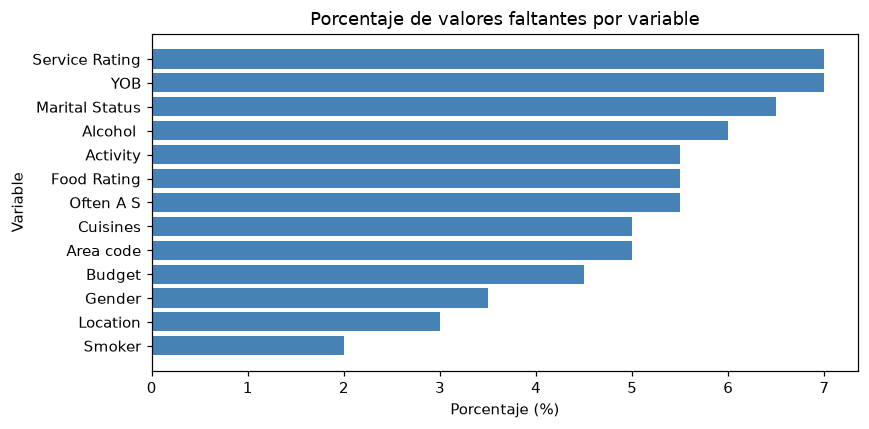

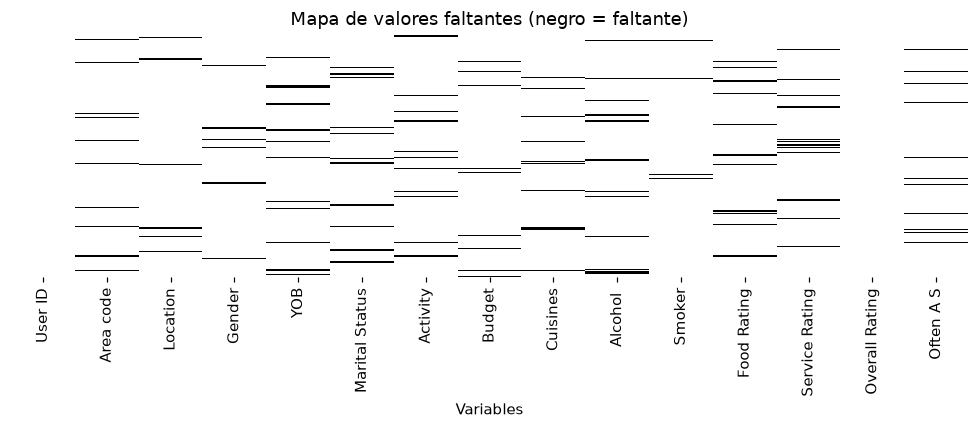

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams['figure.dpi'] = 110

faltantes = pd.DataFrame({
    'Faltantes': df.isna().sum(),
    'Porcentaje (%)': (df.isna().mean() * 100).round(2)
}).sort_values('Porcentaje (%)')
falt_plot = faltantes[faltantes['Faltantes'] > 0]

plt.figure(figsize=(8, 4))
plt.barh(falt_plot.index, falt_plot['Porcentaje (%)'], color='steelblue')
plt.title('Porcentaje de valores faltantes por variable')
plt.xlabel('Porcentaje (%)')
plt.ylabel('Variable')
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 4))
sns.heatmap(df.isna(), cbar=False, yticklabels=False, cmap='Greys')
plt.title('Mapa de valores faltantes (negro = faltante)')
plt.xlabel('Variables')
plt.tight_layout()
plt.show()

Los faltantes van de 2.0% (`Smoker`) a 7.0% (`YOB` y `Service Rating`) y en el mapa aparecen dispersos, sin bloques de filas o columnas vacías. Esto coincide con la correlación de nulos baja de arriba y es compatible con una ausencia aleatoria (MCAR/MAR, en la clasificación de Rubin, 1976). Se mantiene la decisión de tratar los faltantes columna por columna.

##### Valores fuera de rango, inconsistencias, unidades y formatos.

In [18]:
# Ver valores únicos sin NaN en cada columna
resumen_valores = []

for col in df.columns:
    valores = sorted(df[col].dropna().unique())
    resumen_valores.append({'columna': col, 'cant_unicos': len(valores), 'valores': ', '.join(valores)})

tabla_valores = pd.DataFrame(resumen_valores) 
tabla_valores.style.hide(axis='index')

columna,cant_unicos,valores
User ID,200,"1, 10, 100, 101, 102, 103, 104, 105, 106, 107, 108, 109, 11, 110, 111, 112, 113, 114, 115, 116, 117, 118, 119, 12, 120, 121, 122, 123, 124, 125, 126, 127, 128, 129, 13, 130, 131, 132, 133, 134, 135, 136, 137, 138, 139, 14, 140, 141, 142, 143, 144, 145, 146, 147, 148, 149, 15, 150, 151, 152, 153, 154, 155, 156, 157, 158, 159, 16, 160, 161, 162, 163, 164, 165, 166, 167, 168, 169, 17, 170, 171, 172, 173, 174, 175, 176, 177, 178, 179, 18, 180, 181, 182, 183, 184, 185, 186, 187, 188, 189, 19, 190, 191, 192, 193, 194, 195, 196, 197, 198, 199, 2, 20, 200, 21, 22, 23, 24, 25, 26, 27, 28, 29, 3, 30, 31, 32, 33, 34, 35, 36, 37, 38, 39, 4, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 5, 50, 51, 52, 53, 54, 55, 56, 57, 58, 59, 6, 60, 61, 62, 63, 64, 65, 66, 67, 68, 69, 7, 70, 71, 72, 73, 74, 75, 76, 77, 78, 79, 8, 80, 81, 82, 83, 84, 85, 86, 87, 88, 89, 9, 90, 91, 92, 93, 94, 95, 96, 97, 98, 99"
Area code,64,"101, 102, 103, 104, 105, 106, 107, 110, 111, 113, 117, 120, 121, 122, 123, 124, 125, 127, 129, 130, 131, 134, 135, 136, 137, 138, 139, 140, 142, 145, 147, 148, 149, 153, 154, 157, 158, 159, 160, 161, 162, 163, 166, 167, 169, 170, 172, 173, 175, 176, 178, 179, 182, 183, 184, 185, 186, 192, 194, 195, 196, 197, 198, 199"
Location,10,"Cedar Hill, NY, Central Park,NY, Central Park,ny, China Town, NY, Market City, MY, Market City, NY, Riverdale,NY, St. George,NY, Upper East Side,NY, Upper West Side,NY"
Gender,2,"Female, Male"
YOB,46,"1955, 1956, 1957, 1958, 1959, 1960, 1961, 1962, 1963, 1964, 1965, 1967, 1969, 1971, 1974, 1975, 1976, 1977, 1978, 1979, 1980, 1981, 1982, 1983, 1985, 1986, 1987, 1988, 1989, 1990, 1991, 1994, 1995, 1996, 1997, 1998, 1999, 2000, 2001, 2002, 2003, 2004, 2005, 2006, 2007, 2009"
Marital Status,3,"Divorced, Married, Single"
Activity,2,"Professional, Student"
Budget,5,"1, 2, 3, 4, 5"
Cuisines,7,"Chinese, Filipino, French, Indian, Italian, Japanese, Seafood"
Alcohol,3,"Never, Often, Socially"


- Al revisar los valores únicos, formatos y rangos, se ve que todo sigue guardado como string, por lo que las columnas numéricas (User ID, Area code, YOB, Budget, Food Rating, Service Rating y Overall Rating) se ordenan como texto y todavía no tienen su tipo numérico real. 

- En Location hay inconsistencias de escritura y formato, aparecen Central Park,NY y Central Park,ny (distinta capitalización), Market City, MY junto a Market City, NY (posible error de dedo) y variaciones con o sin espacio después de la coma. 

- YOB abarca de 1955 a 2009 sin años fuera de lugar, Budget, Food Rating y Service Rating van del 1 al 5, Overall Rating va del 1 al 5 cada 0.5, no hay unidades explícitas en los datos, y el resto de las variables categóricas tienen categorías claras y sin valores extraños.

Además de los formatos, se revisan dos relaciones internas entre columnas que después sirven para tratar faltantes: si `Overall Rating` es el promedio de `Food Rating` y `Service Rating`, y cómo se relaciona `Often A S` con `Alcohol` y `Smoker`.

In [19]:
from IPython.display import display

ratings = df[['Food Rating', 'Service Rating', 'Overall Rating']].apply(pd.to_numeric, errors='coerce')
completos = ratings.dropna()
dif_max = (completos['Overall Rating'] - (completos['Food Rating'] + completos['Service Rating']) / 2).abs().max()
print(f'Registros con las tres calificaciones: {len(completos)}')
print(f'Diferencia máxima entre Overall Rating y (Food + Service) / 2: {dif_max}')

# 'Alcohol ' todavía tiene el espacio final; se corrige más adelante
display(pd.crosstab([df['Alcohol '].fillna('NaN'), df['Smoker'].fillna('NaN')], df['Often A S'].fillna('NaN')))

Registros con las tres calificaciones: 175
Diferencia máxima entre Overall Rating y (Food + Service) / 2: 0.0


Often A S          NaN  No  Yes
Alcohol  Smoker                
NaN      NaN         0   1    1
         Never       0   4    0
         Often       0   1    0
         Socially    0   5    0
Never    Never       2  24    0
         Often       0  25    0
         Socially    3  29    0
Often    NaN         0   1    0
         Never       1  11    0
         Often       0   0   25
         Socially    0  21    0
Socially NaN         1   0    0
         Never       2  13    0
         Often       2  16    0
         Socially    0  12    0

- En los 175 registros con las tres calificaciones, `Overall Rating` es exactamente el promedio de `Food Rating` y `Service Rating` (diferencia máxima de 0.0). Como `Overall Rating` no tiene faltantes, los huecos de las otras dos calificaciones se pueden recuperar sin estimar nada.
- `Often A S` vale `'Yes'` solo cuando `Alcohol` y `Smoker` son `'Often'` (25 casos) y `'No'` en cualquier otra combinación. Hay un `'Yes'` con ambos hábitos vacíos, así que esos dos valores tienen que ser `'Often'`.
- Por lo tanto, `Often A S`, que era la variable de salida original del dataset, no aporta información propia: es un resumen de `Alcohol` y `Smoker`. Su regla se usa en la Etapa 4 para imputar esos hábitos y después se elimina de `df_limpio`.
- La relación exacta de `Overall Rating` también implica que `Food Rating` y `Service Rating` no pueden ser predictoras de la satisfacción (ver la sección de fuga de información).

##### Distribuciones, categorías raras, desequilibrio de clases y posibles valores atípicos.
Para no complicarnos, primero revisamos conteos y porcentajes en las variables categóricas y en Often A S (donde ya sabemos que predomina 'No'), y también revisamos los números que parecen más continuos/discretos (YOB, Budget, Food Rating, Service Rating, Overall Rating) para ver si hay valores raros o extremos.

In [20]:
#Frecuencias y porcentajes (categorías raras y desequilibrio)
cols_cat = ['Location', 'Gender', 'Marital Status', 'Activity', 'Budget', 'Cuisines', 'Alcohol ', 'Smoker', 'Food Rating', 'Service Rating', 'Overall Rating', 'Often A S']

for col in cols_cat:
    print({col})
    conteo = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(dropna=False, normalize=True) * 100)
    tabla = pd.DataFrame({'categoria': conteo.index, 'conteo': conteo.values, 'porcentaje': pct.values})
    display(tabla.style.hide(axis='index').format({'porcentaje': '{:.1f}'}))

{'Location'}


categoria,conteo,porcentaje
"St. George,NY",45,22.5
"Upper East Side,NY",29,14.5
"Riverdale,NY",28,14.0
"Central Park,NY",24,12.0
"China Town, NY",20,10.0
"Market City, NY",20,10.0
"Upper West Side,NY",16,8.0
"Central Park,ny",8,4.0
nan,6,3.0
"Market City, MY",2,1.0


{'Gender'}


categoria,conteo,porcentaje
Male,114,57.0
Female,79,39.5
nan,7,3.5


{'Marital Status'}


categoria,conteo,porcentaje
Single,89,44.5
Married,84,42.0
Divorced,14,7.0
nan,13,6.5


... (14 outputs left out)

{'Overall Rating'}


categoria,conteo,porcentaje
3.5,35,17.5
3,34,17.0
2.5,32,16.0
5,29,14.5
4,26,13.0
2,21,10.5
1.5,11,5.5
4.5,6,3.0
1,6,3.0


{'Often A S'}


categoria,conteo,porcentaje
No,163,81.5
Yes,26,13.0
nan,11,5.5


Al revisar frecuencias y distribuciones, se observa:
- Un desequilibrio muy grande en Often A S, donde 'No' concentra el 81.5% con 163 registros frente a 'Yes' con 13.0% (26) y nan con 5.5% (11). 
- En Location, destacan Market City, MY y Cedar Hill, NY con 1.0% (2 casos cada una), además de Central Park,ny (4.0%, 8 casos) separada de Central Park,NY (12.0%, 24 casos).
- En Budget, el valor 2 tiene solo 2.0% (4 casos) frente a 3, 4 y 5 con 29.5% cada uno, y en Overall Rating, 1 y 4.5 son los menos frecuentes (3.0% cada uno), aunque dentro de la escala esperada. 
- El resto de las variables (Gender, Marital Status, Activity, Cuisines, Alcohol , Smoker, Food Rating y Service Rating) muestran distribuciones razonablemente repartidas sin valores extremos fuera de rango.

Como todavía están como str, las convertimos temporalmente a número solo para inspeccionar su distribución básica

In [21]:
#Revisión rápida de números (YOB y calificaciones) para posibles atípicos
cols_num = ['YOB', 'Budget', 'Food Rating', 'Service Rating', 'Overall Rating']

for col in cols_num:
    s = pd.to_numeric(df[col], errors='coerce').dropna().sort_values()
    conteo = s.value_counts().sort_index()
    tabla = pd.DataFrame({'valor': conteo.index, 'conteo': conteo.values})
    print(col)
    display(tabla.style.hide(axis='index').format({'valor': '{:.0f}'}))

YOB


valor,conteo
1955,4
1956,6
1957,2
1958,2
1959,3
1960,2
1961,4
1962,3
1963,4
1964,4


Budget


valor,conteo
1,10
2,4
3,59
4,59
5,59


Food Rating


valor,conteo
1,28
2,32
3,44
4,33
5,52


Service Rating


valor,conteo
1,34
2,38
3,28
4,25
5,61


Overall Rating


valor,conteo
1,6
2,11
2,21
2,32
3,34
4,35
4,26
4,6
5,29


En la inspección numérica de YOB, Budget, Food Rating, Service Rating y Overall Rating no se detectan valores atípicos fuera de rango o imposibles: YOB abarca de 1955 a 2009 (con bajas frecuencias en años puntuales como 1990 con 1 registro), y las variables de presupuesto y calificación se mantienen dentro de sus escalas esperadas de 1 a 5.

Para complementar los conteos se calculan los límites de Tukey (`Q1 - 1.5*IQR` y `Q3 + 1.5*IQR`) y se grafican histogramas y diagramas de caja de las mismas variables.

Variable,Media,Mediana,Desv. Est.,Mín,Q1,Q3,Máx,Lím. Inf. IQR,Lím. Sup. IQR,Atípicos
YOB,1984.630000,1987.000000,16.860000,1955.000000,1971.000000,2000.000000,2009.000000,1927.500000,2043.500000,0
Budget,3.800000,4.000000,1.070000,1.000000,3.000000,5.000000,5.000000,0.000000,8.000000,0
Food Rating,3.260000,3.000000,1.410000,1.000000,2.000000,5.000000,5.000000,-2.500000,9.500000,0
Service Rating,3.220000,3.000000,1.530000,1.000000,2.000000,5.000000,5.000000,-2.500000,9.500000,0
Overall Rating,3.220000,3.000000,1.080000,1.000000,2.500000,4.000000,5.000000,0.250000,6.250000,0


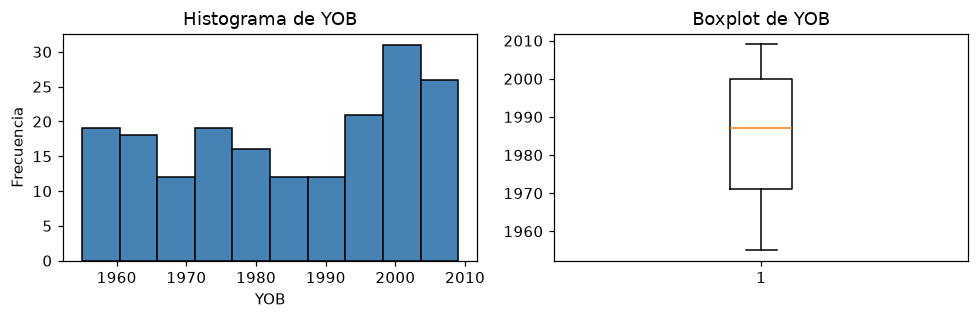

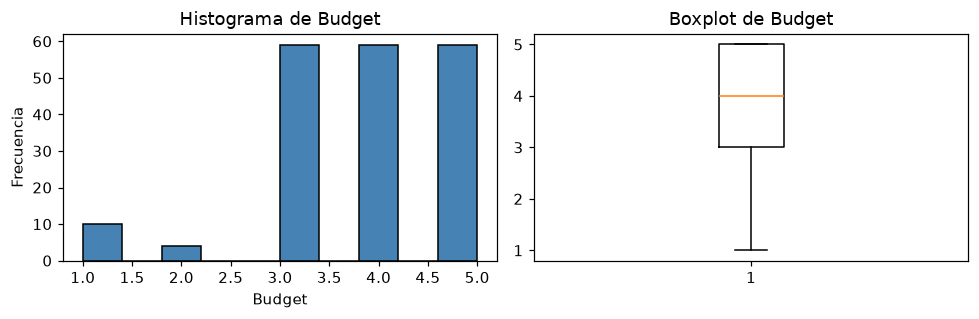

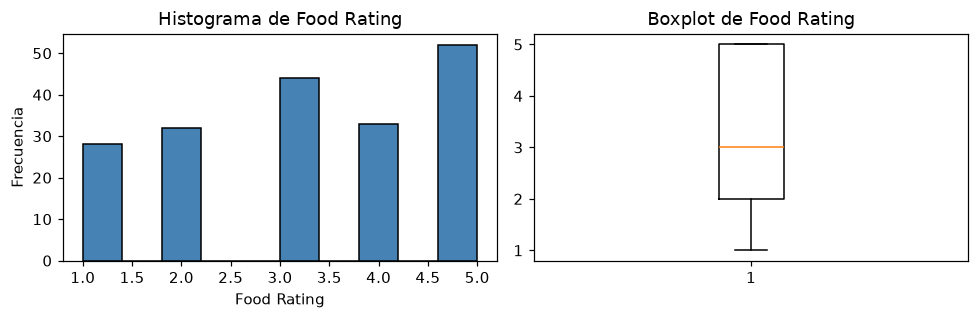

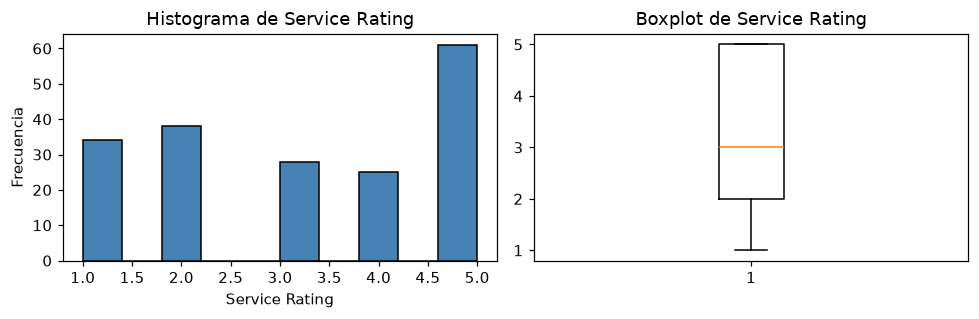

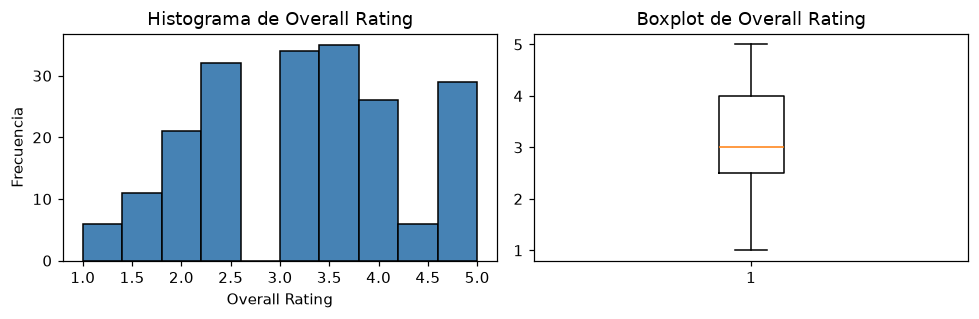

In [22]:
resumen_num = []
for col in cols_num:
    s = pd.to_numeric(df[col], errors='coerce').dropna()
    q1, med, q3 = s.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    resumen_num.append({
        'Variable': col, 'Media': round(s.mean(), 2), 'Mediana': med, 'Desv. Est.': round(s.std(), 2),
        'Mín': s.min(), 'Q1': q1, 'Q3': q3, 'Máx': s.max(),
        'Lím. Inf. IQR': lim_inf, 'Lím. Sup. IQR': lim_sup,
        'Atípicos': int(((s < lim_inf) | (s > lim_sup)).sum())
    })
display(pd.DataFrame(resumen_num).style.hide(axis='index'))

for col in cols_num:
    s = pd.to_numeric(df[col], errors='coerce').dropna()
    plt.figure(figsize=(9, 3))
    plt.subplot(1, 2, 1)
    plt.hist(s, bins=10, color='steelblue', edgecolor='black')
    plt.title(f'Histograma de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')
    plt.subplot(1, 2, 2)
    plt.boxplot(s)
    plt.title(f'Boxplot de {col}')
    plt.tight_layout()
    plt.show()

Ninguna de las cinco variables tiene valores fuera de los límites de Tukey; en las calificaciones los límites caen incluso fuera de la escala (por ejemplo, -2.5 a 9.5 en `Food Rating`) porque el rango intercuartílico es amplio. En los histogramas, `YOB` se carga hacia los nacidos después de 1995, `Budget` casi no tiene valores 1 y 2, y `Service Rating` está más polarizada que `Food Rating` (muchos 1, 2 y 5).

##### Limpieza de inconsistencias y conversión de tipos de datos

Ahora vamos a dejar la tabla ordenada y con tipos de datos adecuados antes de seguir avanzando

1. **Limpiar nombres de columnas:** Quitar espacios sobrantes en los encabezados, como el espacio final en 'Alcohol ' para dejarlo como 'Alcohol'.
2. **Estandarizar textos en Location:** Unificar variaciones de escritura y formato como Central Park,NY y Central Park,ny, normalizar el formato de la coma y revisar qué hacer con Market City, MY.
3. **Convertir columnas numéricas a su tipo real:** Pasar User ID, Area code, YOB, Budget, Food Rating, Service Rating y Overall Rating de texto a su formato numérico correspondiente ya sea Int o float, conservando bien los valores faltantes (NaN).
4. **Verificar el resultado:** Revisar con una tabla rápida que los nombres, categorías y tipos de datos quedaron como esperábamos sin perder registros.

**Limpiar nombres de columnas**

In [23]:
df.columns = df.columns.str.strip()
print(df.columns,'\n')
print('Confirmación clara de Alcohol:\n',df.columns.where(df.columns == 'Alcohol'))

Index(['User ID', 'Area code', 'Location', 'Gender', 'YOB', 'Marital Status',
       'Activity', 'Budget', 'Cuisines', 'Alcohol', 'Smoker', 'Food Rating',
       'Service Rating', 'Overall Rating', 'Often A S'],
      dtype='str') 

Confirmación clara de Alcohol:
 Index([nan, nan, nan, nan, nan, nan, nan, nan, nan, 'Alcohol', nan, nan, nan,
       nan, nan],
      dtype='str')


In [24]:
#Revisar Location antes de estandarizar. Ver exactamente qué categorías tiene y cómo están escritas respetando los NaN
conteo_loc = df['Location'].value_counts(dropna=False)
tabla_loc = pd.DataFrame({'Location': conteo_loc.index, 'conteo': conteo_loc.values})
display(tabla_loc.style.hide(axis='index'))

Location,conteo
"St. George,NY",45
"Upper East Side,NY",29
"Riverdale,NY",28
"Central Park,NY",24
"China Town, NY",20
"Market City, NY",20
"Upper West Side,NY",16
"Central Park,ny",8
nan,6
"Market City, MY",2


In [25]:
# Estandarizar espacios y formato de 'Location' manteniendo NaN
df['Location'] = (
    df['Location']
    .str.strip()
    .str.replace(r'\s*,\s*', ', ', regex=True)
    .str.replace(r',\s*ny$', ', NY', case=False, regex=True)
)

In [26]:
df[df['Location'] == 'Market City, MY']

,User ID,Area code,Location,Gender,YOB,Marital Status,Activity,Budget,Cuisines,Alcohol,Smoker,Food Rating,Service Rating,Overall Rating,Often A S
31,32,154,"Market City, MY",Male,1971,Married,Student,1,Indian,Never,Often,4,2,3,No
131,132,159,"Market City, MY",Male,1971,Married,Student,1,Indian,Never,Often,4,2,3,No


**Decisión sobre Market City, MY:**  
Se decidió tratar Market City, MY como un error de dedo para referirse a Market City, NY y unificarlo con esta última por las siguientes razones:

- Todas las demás ubicaciones válidas de la columna pertenecen a Nueva York (NY), y no existe ningún estado de Estados Unidos con abreviatura postal MY.
- Market City, NY ya aparece en el conjunto de datos con 20 registros, mientras que Market City, MY solo ocurre en 2 casos.
- La tecla M se encuentra justo al lado de la N en el teclado, y en la misma columna ya se detectaron otros descuidos manuales de escritura como Central Park,ny en minúsculas e inconsistencias de espaciado después de la coma.

Por lo tanto:

In [27]:
df['Location'] = df['Location'].replace({'Market City, MY': 'Market City, NY'})

In [28]:
conteo_loc_limpio = df['Location'].value_counts(dropna=False)
tabla_loc_limpia = pd.DataFrame({
    'Location': conteo_loc_limpio.index,
    'conteo': conteo_loc_limpio.values
})
display(tabla_loc_limpia.style.hide(axis='index'))

Location,conteo
"St. George, NY",45
"Central Park, NY",32
"Upper East Side, NY",29
"Riverdale, NY",28
"Market City, NY",22
"China Town, NY",20
"Upper West Side, NY",16
nan,6
"Cedar Hill, NY",2


**Convertir formalmente las columnas numéricas a su tipo real**

Con los encabezados limpios y Location estandarizada, el paso que sigue en nuestro plan es convertir las variables que vienen como string a sus tipos numéricos correspondientes. 

In [29]:
cols_enteras = ['User ID', 'Area code', 'YOB', 'Budget']
cols_decimales = ['Food Rating', 'Service Rating', 'Overall Rating']

for col in cols_enteras:
    df[col] = pd.to_numeric(df[col], errors='coerce').astype('Int64')

for col in cols_decimales:
    df[col] = pd.to_numeric(df[col], errors='coerce').astype('float64')

tabla_tipos = pd.DataFrame({
    'columna': df.columns,
    'tipo_dato': df.dtypes.astype(str).values,
    'nulos': df.isna().sum().values
})
display(tabla_tipos.style.hide(axis='index'))

columna,tipo_dato,nulos
User ID,Int64,0
Area code,Int64,10
Location,str,6
Gender,str,7
YOB,Int64,14
Marital Status,str,13
Activity,str,11
Budget,Int64,9
Cuisines,str,10
Alcohol,str,12


##### Variables que podrían filtrar información futura o identificar directamente a una persona.
No se incluyen datos de contacto o identificación directa como nombre, correo o teléfono. User ID actúa como identificador de registro, por lo que debe tratarse como ID y no como variable predictora, mientras que la combinación de variables demográficas y geográficas (Location, Area code, YOB, Gender, Marital Status, Activity) podría dar cierto nivel de perfilado en segmentos reducidos.

**Fuga de información respecto al objetivo.** La variable objetivo es `Calificacion_Alta`, que se construye con `Overall Rating`. Como `Overall Rating` es exactamente `(Food Rating + Service Rating) / 2`, esas dos calificaciones y la variable derivada `Dif_Comida_Servicio` contienen al objetivo: un modelo que las use separaría las clases casi perfecto, pero solo porque ya tiene la respuesta. Además, se capturan en el mismo momento que la calificación general, así que no estarían disponibles antes de que el cliente califique. Por eso, junto con `Overall Rating`, quedan fuera de las predictoras en la Etapa 5.

`Often A S` era la salida original del dataset, pero se deriva de `Alcohol` y `Smoker` y no aporta al objetivo actual; se elimina en la Etapa 4 después de usarla para imputar. No hay variables de tiempo futuro porque el archivo no tiene fechas.

##### Diccionario de datos

| Variable | Descripción | Tipo | Categoría | Papel en el análisis |
| :--- | :--- | :--- | :--- | :--- |
| User ID | Identificador del cliente | entero | identificador | Identificador de registro (excluir como predictor) |
| Area code | Código de área de residencia del cliente | entero | nominal | Contexto geográfico (no entra como predictor; la ubicación se representa con `Ciudad`) |
| Location | Zona y ciudad de residencia del cliente | texto | nominal | Predictor categórico (foco de representación categórica) |
| Gender | Género del cliente | texto | nominal | Predictor demográfico (foco de representación categórica) |
| YOB | Año de nacimiento del cliente | entero | discreta | Predictor demográfico |
| Marital Status | Estado civil del cliente | texto | nominal | Predictor demográfico (foco de representación categórica) |
| Activity | Situación laboral o académica (estudiante o profesionista) | texto | nominal | Predictor demográfico/ocupacional (foco de representación categórica) |
| Budget | Presupuesto estimado a gastar en el restaurante | entero | discreta / ordinal | Predictor de gasto |
| Cuisines | Tipo de cocina preferida en restaurante | texto | nominal | Predictor de preferencia (foco de representación categórica) |
| Alcohol | Frecuencia de consumo de alcohol | texto | ordinal | Predictor de hábito (foco de representación categórica) |
| Smoker | Hábito o frecuencia de fumar | texto | ordinal / nominal | Predictor de hábito (foco de representación categórica) |
| Food Rating | Calificación de la comida | decimal | discreta / ordinal | Componente del objetivo; excluida como predictor (fuga) |
| Service Rating | Calificación del servicio | decimal | discreta / ordinal | Componente del objetivo; excluida como predictor (fuga) |
| Overall Rating | Calificación general = (Food + Service) / 2 | decimal | discreta / ordinal | Variable objetivo (define `Calificacion_Alta`) |
| Often A S | Consumo frecuente de alcohol y tabaco ('Yes' solo si Alcohol y Smoker son 'Often') | texto | binaria | Salida original del dataset; solo se usa para imputar hábitos y se elimina en la Etapa 4 |
| Calificacion_Alta | Satisfacción alta: 1 si Overall Rating >= 4, 0 si no (se crea en la Etapa 4) | entero | binaria | Variable objetivo |

## Etapa 4. Limpieza, transformación y construcción de características: Módulo II

Justifiquen y documenten solo los procedimientos que correspondan a los datos:

- **Faltantes:** decidir si se conserva el registro, se imputa o se crea un indicador, explicar la elección
- **Atípicos y rangos:** distinguir un valor extremo válido de un error. Documentar reglas de detección y cualquier tratamiento, no eliminarlos automáticamente.
- **Escalas:** comparar unidades y distribuciones. Estandarización o normalización se ajustan en entrenamiento y se aplican sin recalcular a prueba.
- **Enriquecimiento:** crear variables derivadas que tengan sentido para la pregunta y explicar la fórmula.
- **Categóricas nominales:** considerar variables dummy/one-hot, no inventar un orden.
- **Categóricas ordinales:** definir y justificar el orden antes de codificar, las distancias numéricas implicadas también requieren justificación.
- **Variables polinomiales:** usarlas para representar curvatura cuando exista una razón.

Registren antes y después: tipos, dimensiones, faltantes y ejemplos de filas. Si no aplican una técnica, indiquen brevemente por qué no es pertinente.

### Metodología elegida

Antes de continuar se compararon los dos enfoques del equipo (este notebook y la versión alterna `Guia_Proyecto_Final_Equipo3.ipynb`). Se conserva un solo camino:

| Paso | Versión base | Versión alterna | Se conserva |
|---|---|---|---|
| Limpieza de `Location` | regex sin distinguir mayúsculas y reemplazo explícito de `Market City, MY` | reemplazo de cadenas fijas (`', MY'` → `', NY'`) | Base: la corrección es más específica y está justificada caso por caso |
| Conversión de tipos | `Int64` para enteros (admite `NaN`) y `float64` para calificaciones | todo a `float` | Base: conserva enteros sin perder faltantes |
| Atípicos | conteo de valores por variable | límites de Tukey e histogramas/boxplots | Ambos (ya integrados en la Etapa 3) |
| Faltantes | no desarrollado | reconstrucción exacta de calificaciones, deducción lógica de hábitos, mediana vs. KNN y moda | Alterna, con un cambio en `Cuisines` (ver 4.2) |
| Escalas, codificación, selección y PCA | no desarrollado | comparación de escaladores, codificación ordinal/dummy, Spearman y PCA | Alterna, agregando `VarianceThreshold` y la regla de filtrado por correlación del Módulo III |

La razón principal para tomar el tratamiento de faltantes de la versión alterna es que no inventa valores cuando se pueden recuperar exactamente de otras columnas.

### 4.1 Copia de trabajo y estado inicial

La limpieza de encabezados, la estandarización de `Location` y la conversión de tipos ya se hicieron en la Etapa 3 sobre `df` (`df_orig` conserva la versión cruda). Aquí se crea `df_limpio` para tratar faltantes y construir variables sin modificar `df`.

In [30]:
df_limpio = df.copy(deep=True)

def resumen_estado(datos):
    return pd.DataFrame({'tipo': datos.dtypes.astype(str), 'faltantes': datos.isna().sum()})

estado_antes = resumen_estado(df_limpio)
print('Dimensiones antes de la Etapa 4:', df_limpio.shape)
print('Faltantes totales:', df_limpio.isna().sum().sum())

Dimensiones antes de la Etapa 4: (200, 15)
Faltantes totales: 132


### 4.2 Tratamiento de valores faltantes

Como los faltantes son pocos (2% a 7% por columna) y están dispersos, no se eliminan filas. Se aplica una estrategia en tres niveles:

1. **Reconstrucción exacta de calificaciones.** Como `Overall Rating = (Food Rating + Service Rating) / 2` y `Overall Rating` no tiene faltantes, el valor que falta se recupera con `2 * Overall Rating - otra_calificacion`.
2. **Deducción lógica de hábitos.** Si `Often A S == 'Yes'`, `Alcohol` y `Smoker` deben ser `'Often'`. Si `Often A S` falta pero alguno de los dos hábitos es `'Never'` o `'Socially'`, entonces `Often A S` es `'No'`.
3. **Imputación de lo que queda.**
   - `Area code`, `YOB` y `Budget`: se comparan mediana y `KNNImputer(n_neighbors=5)` (estandarizando antes de medir distancias).
   - `Location`, `Gender`, `Marital Status`, `Activity`, `Alcohol` y `Smoker`: moda, porque la ausencia es baja y no conviene crear categorías con pocos casos. En `Alcohol` y `Smoker` hay una restricción: si `Often A S` es `'No'` y el otro hábito es `'Often'`, el faltante no puede ser `'Often'`, así que se usa la moda de los demás niveles.
   - `Cuisines`: se llena con la categoría constante `'Desconocido'` en lugar de la moda. Es la variable central del proyecto y en los datos crudos `Japanese` (34) y `Filipino` (33) casi empatan; imputar los 10 faltantes con la moda le daría a `Japanese` una ventaja artificial de 11 clientes. Estos registros se excluyen en los análisis por tipo de cocina.

Al terminar, `Often A S` ya no se necesita y se elimina en 4.3.

In [31]:
from sklearn.impute import KNNImputer, SimpleImputer
from sklearn.preprocessing import StandardScaler

# 1. Reconstrucción exacta de Food Rating y Service Rating
mask_food_na = df_limpio['Food Rating'].isna() & df_limpio['Service Rating'].notna()
mask_serv_na = df_limpio['Service Rating'].isna() & df_limpio['Food Rating'].notna()
df_limpio.loc[mask_food_na, 'Food Rating'] = 2 * df_limpio.loc[mask_food_na, 'Overall Rating'] - df_limpio.loc[mask_food_na, 'Service Rating']
df_limpio.loc[mask_serv_na, 'Service Rating'] = 2 * df_limpio.loc[mask_serv_na, 'Overall Rating'] - df_limpio.loc[mask_serv_na, 'Food Rating']
print(f'Food Rating reconstruidos: {mask_food_na.sum()}')
print(f'Service Rating reconstruidos: {mask_serv_na.sum()}')
print('Rango de calificaciones reconstruidas:',
      df_limpio[['Food Rating', 'Service Rating']].min().min(), 'a', df_limpio[['Food Rating', 'Service Rating']].max().max())

# 2. Deducción lógica de Alcohol, Smoker y Often A S
mask_yes_alc = (df_limpio['Often A S'] == 'Yes') & df_limpio['Alcohol'].isna()
mask_yes_smk = (df_limpio['Often A S'] == 'Yes') & df_limpio['Smoker'].isna()
df_limpio.loc[mask_yes_alc, 'Alcohol'] = 'Often'
df_limpio.loc[mask_yes_smk, 'Smoker'] = 'Often'

mask_oas_no = df_limpio['Often A S'].isna() & (
    df_limpio['Alcohol'].isin(['Never', 'Socially']) | df_limpio['Smoker'].isin(['Never', 'Socially'])
)
df_limpio.loc[mask_oas_no, 'Often A S'] = 'No'
print(f'Alcohol/Smoker deducidos desde Often A S = Yes: {mask_yes_alc.sum() + mask_yes_smk.sum()}')
print(f'Often A S deducidos como No: {mask_oas_no.sum()}')
print(f'Often A S faltantes restantes: {df_limpio["Often A S"].isna().sum()}')

Food Rating reconstruidos: 11
Service Rating reconstruidos: 14
Rango de calificaciones reconstruidas: 1.0 a 5.0
Alcohol/Smoker deducidos desde Often A S = Yes: 2
Often A S deducidos como No: 11
Often A S faltantes restantes: 0


Variable,Mediana_Orig,Std_Orig,Mediana_Med,Std_Med,Mediana_KNN,Std_KNN
Area code,135.000000,25.960000,135.000000,25.330000,136.000000,25.360000
YOB,1987.000000,16.860000,1987.000000,16.270000,1985.100000,16.340000
Budget,4.000000,1.070000,4.000000,1.040000,4.000000,1.050000


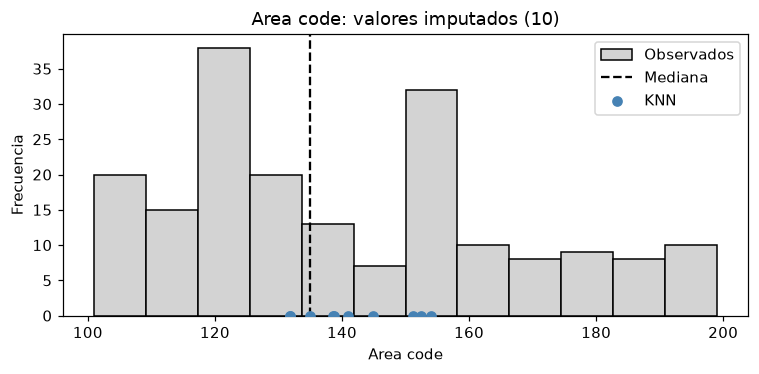

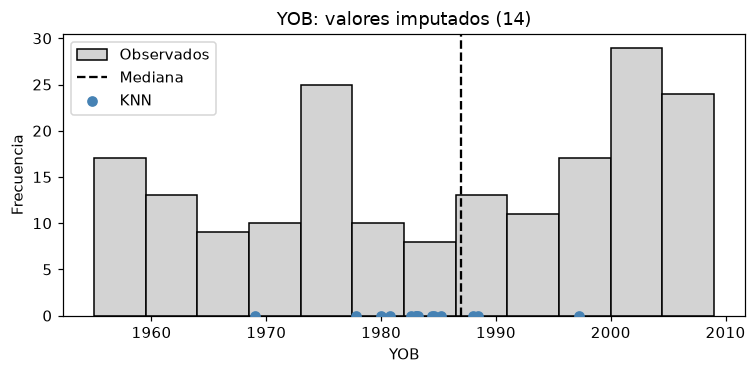

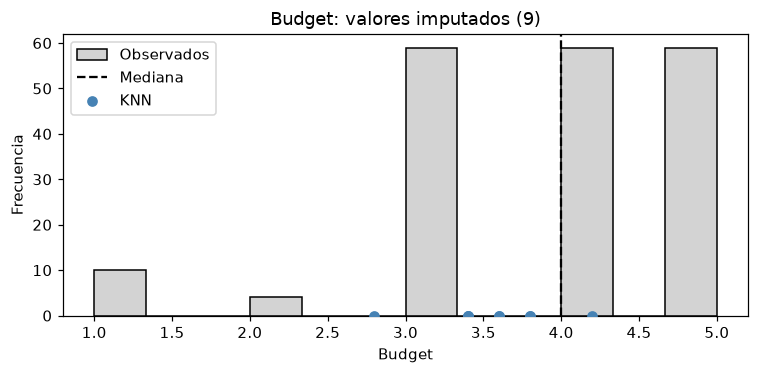

In [32]:
# 3. Comparación mediana vs KNNImputer(n_neighbors=5) para Area code, YOB y Budget
cols_imp_num = ['Area code', 'YOB', 'Budget']
datos_num = df_limpio[cols_imp_num].astype('float64')

df_mediana = pd.DataFrame(SimpleImputer(strategy='median').fit_transform(datos_num),
                          columns=cols_imp_num, index=df_limpio.index)

scaler_imp = StandardScaler()
datos_std = scaler_imp.fit_transform(datos_num)
datos_knn_std = KNNImputer(n_neighbors=5).fit_transform(datos_std)
df_knn = pd.DataFrame(scaler_imp.inverse_transform(datos_knn_std), columns=cols_imp_num, index=df_limpio.index)

comp_imp = []
for c in cols_imp_num:
    obs = datos_num[c].dropna()
    comp_imp.append({
        'Variable': c,
        'Mediana_Orig': obs.median(), 'Std_Orig': round(obs.std(), 2),
        'Mediana_Med': df_mediana[c].median(), 'Std_Med': round(df_mediana[c].std(), 2),
        'Mediana_KNN': round(df_knn[c].median(), 2), 'Std_KNN': round(df_knn[c].std(), 2),
    })
display(pd.DataFrame(comp_imp).style.hide(axis='index'))

# Dónde caen los valores imputados por cada método respecto a la distribución observada
for c in cols_imp_num:
    faltan = datos_num[c].isna()
    plt.figure(figsize=(7, 3.5))
    plt.hist(datos_num[c].dropna(), bins=12, color='lightgray', edgecolor='black', label='Observados')
    plt.axvline(datos_num[c].median(), color='black', linestyle='--', label='Mediana')
    plt.scatter(df_knn.loc[faltan, c], [0] * faltan.sum(), color='steelblue', zorder=3, label='KNN')
    plt.title(f'{c}: valores imputados ({faltan.sum()})')
    plt.xlabel(c)
    plt.ylabel('Frecuencia')
    plt.legend()
    plt.tight_layout()
    plt.show()

Las dos opciones conservan casi igual la mediana y la desviación estándar, porque solo se imputan entre 9 y 14 valores por columna. La diferencia está en los valores que generan: KNN produce decimales (en `Budget` aparecen valores como 2.8 o 3.4, y en `YOB` años como 1985.1) que no existen en variables enteras, mientras que la mediana deja un valor válido de la escala. Se usa la **mediana** en `Area code`, `YOB` y `Budget`.

In [33]:
import numpy as np

# Mediana para numéricas (se regresan a entero porque ya no tienen faltantes)
for c in cols_imp_num:
    print(f'Imputados en {c}: {df_limpio[c].isna().sum()} celdas con mediana = {df_mediana[c].median()}')
    df_limpio[c] = df_mediana[c].astype('int64')

# Alcohol y Smoker: si Often A S = 'No' y el otro hábito es 'Often', el faltante no puede ser 'Often'
for c, otro in [('Alcohol', 'Smoker'), ('Smoker', 'Alcohol')]:
    restringido = df_limpio[c].isna() & (df_limpio['Often A S'] == 'No') & (df_limpio[otro] == 'Often')
    if restringido.any():
        moda_sin_often = df_limpio.loc[df_limpio[c] != 'Often', c].mode().iloc[0]
        df_limpio.loc[restringido, c] = moda_sin_often
        print(f"Imputados en {c}: {restringido.sum()} celdas con '{moda_sin_often}' (moda sin 'Often', por la regla de Often A S)")

# Moda para el resto de las categóricas
cols_imp_cat = ['Location', 'Gender', 'Marital Status', 'Activity', 'Alcohol', 'Smoker', 'Often A S']
for c in cols_imp_cat:
    n_imp = df_limpio[c].isna().sum()
    if n_imp > 0:
        moda = df_limpio[c].mode().iloc[0]
        df_limpio[c] = df_limpio[c].fillna(moda)
        print(f"Imputados en {c}: {n_imp} celdas con moda = '{moda}'")

# Constante para Cuisines
print(f"Imputados en Cuisines: {df_limpio['Cuisines'].isna().sum()} celdas con 'Desconocido'")
df_limpio['Cuisines'] = df_limpio['Cuisines'].fillna('Desconocido')

df_limpio['User ID'] = df_limpio['User ID'].astype('int64')

# La imputación no debe romper la regla de Often A S
regla = np.where((df_limpio['Alcohol'] == 'Often') & (df_limpio['Smoker'] == 'Often'), 'Yes', 'No')
print('\nRegistros que no cumplen la regla de Often A S:', (df_limpio['Often A S'] != regla).sum())

estado_despues = resumen_estado(df_limpio)
display(estado_antes.join(estado_despues, lsuffix=' antes', rsuffix=' después'))
print('Faltantes totales después de la limpieza:', df_limpio.isna().sum().sum())

Imputados en Area code: 10 celdas con mediana = 135.0
Imputados en YOB: 14 celdas con mediana = 1987.0
Imputados en Budget: 9 celdas con mediana = 4.0
Imputados en Alcohol: 1 celdas con 'Never' (moda sin 'Often', por la regla de Often A S)
Imputados en Smoker: 1 celdas con 'Socially' (moda sin 'Often', por la regla de Often A S)
Imputados en Location: 6 celdas con moda = 'St. George, NY'
Imputados en Gender: 7 celdas con moda = 'Male'
Imputados en Marital Status: 13 celdas con moda = 'Single'
Imputados en Activity: 11 celdas con moda = 'Student'
Imputados en Alcohol: 10 celdas con moda = 'Never'
Imputados en Smoker: 2 celdas con moda = 'Socially'
Imputados en Cuisines: 10 celdas con 'Desconocido'

Registros que no cumplen la regla de Often A S: 0


,tipo antes,faltantes antes,tipo después,faltantes después
User ID,Int64,0,int64,0
Area code,Int64,10,int64,0
Location,str,6,str,0
Gender,str,7,str,0
YOB,Int64,14,int64,0
Marital Status,str,13,str,0
Activity,str,11,str,0
Budget,Int64,9,int64,0
Cuisines,str,10,str,0
Alcohol,str,12,str,0


Faltantes totales después de la limpieza: 0


### 4.3 Retiro de `Often A S` y variable objetivo

`Often A S` se retira de `df_limpio` porque era la variable de salida original del dataset y no aporta al objetivo actual: ya se usó para recuperar `Alcohol` y `Smoker`, y lo que contiene está en esas dos columnas.

Se crea el objetivo `Calificacion_Alta = 1` si `Overall Rating >= 4`. Esta columna es la etiqueta: no se escala ni entra en la matriz de predictoras `X`.

¿'Often A S' sigue en df_limpio?: False


,Clientes,Porcentaje (%)
Calificacion_Alta,,
0,139,69.5
1,61,30.5


Calificacion_Alta,0,1
Overall Rating,,
1.0,6,0
1.5,11,0
2.0,21,0
2.5,32,0
3.0,34,0
3.5,35,0
4.0,0,26
4.5,0,6
5.0,0,29


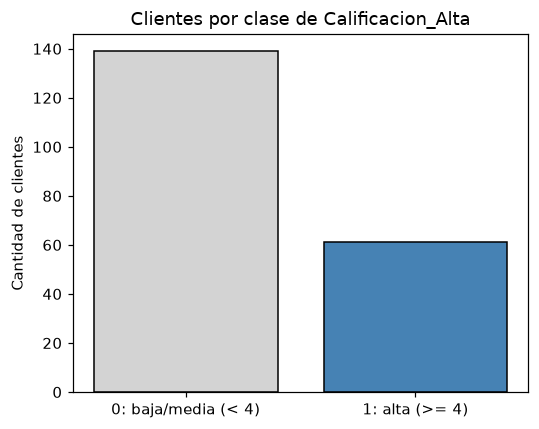

In [34]:
df_limpio = df_limpio.drop(columns=['Often A S'])
df_limpio['Calificacion_Alta'] = (df_limpio['Overall Rating'] >= 4).astype(int)

print("¿'Often A S' sigue en df_limpio?:", 'Often A S' in df_limpio.columns)
clases_obj = df_limpio['Calificacion_Alta'].value_counts().sort_index()
display(pd.DataFrame({'Clientes': clases_obj,
                      'Porcentaje (%)': (clases_obj / len(df_limpio) * 100).round(1)}))
display(pd.crosstab(df_limpio['Overall Rating'], df_limpio['Calificacion_Alta']))

plt.figure(figsize=(5, 4))
plt.bar(['0: baja/media (< 4)', '1: alta (>= 4)'], clases_obj.values, color=['lightgray', 'steelblue'], edgecolor='black')
plt.title('Clientes por clase de Calificacion_Alta')
plt.ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()

`Often A S` ya quedó fuera de `df_limpio`. La variable objetivo `Calificacion_Alta` queda con **139 clientes en la clase 0** (69.5%, con `Overall Rating` de 1.0 a 3.5) y **61 clientes en la clase 1** (30.5%, con `Overall Rating` de 4.0 a 5.0). Como existe un desbalance moderado (~70% / 30%), en la Etapa 5 se usa partición estratificada en LDA y se compara su exactitud contra la referencia de predecir siempre la clase mayoritaria (0.700).

### 4.4 Atípicos y rangos

Con los límites de Tukey de la Etapa 3 no se encontraron valores atípicos, y todas las variables están dentro de escalas válidas (`Budget` y calificaciones de 1 a 5, `YOB` de 1955 a 2009). Las calificaciones reconstruidas en 4.2 también quedaron entre 1 y 5. Por eso no se elimina ni se recorta ningún registro.

### 4.5 Enriquecimiento y variables derivadas

Se crean variables que ayudan a responder las preguntas del proyecto:
- `Edad = 2026 - YOB`: edad aproximada al año del análisis.
- `Grupo_Edad`: tramos `<25`, `25-39`, `40-54` y `55+` para comparar segmentos.
- `Ciudad`: la parte de `Location` antes de la coma. No se crea una columna de estado porque todas las ubicaciones son de NY y sería constante.
- `Dif_Comida_Servicio = Food Rating - Service Rating`: brecha entre ambas calificaciones (positiva si la comida se calificó mejor que el servicio). Solo se usa en el análisis descriptivo: como depende de `Food Rating` y `Service Rating`, no entra como predictora de `Calificacion_Alta`.

Estados distintos en Location: ['NY']


,User ID,YOB,Edad,Grupo_Edad,Location,Ciudad,Food Rating,Service Rating,Dif_Comida_Servicio
0,1,2006,20,<25,"Upper East Side, NY",Upper East Side,5.0,4.0,1.0
1,2,1991,35,25-39,"St. George, NY",St. George,1.0,1.0,0.0
2,3,1977,49,40-54,"St. George, NY",St. George,5.0,5.0,0.0
3,4,1956,70,55+,"Upper East Side, NY",Upper East Side,3.0,1.0,2.0
4,5,1997,29,25-39,"Central Park, NY",Central Park,2.0,4.0,-2.0
5,6,1995,31,25-39,"China Town, NY",China Town,5.0,1.0,4.0


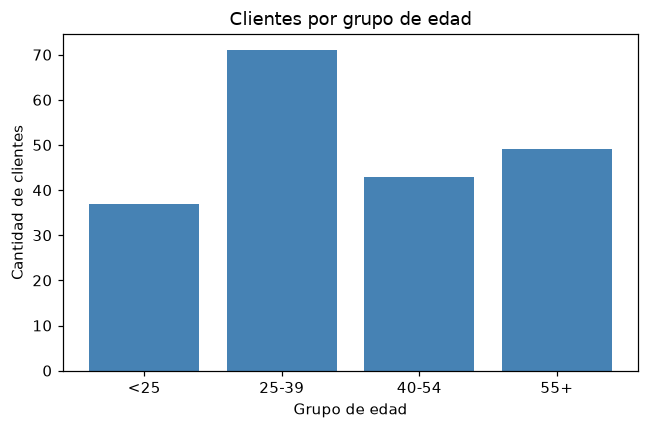

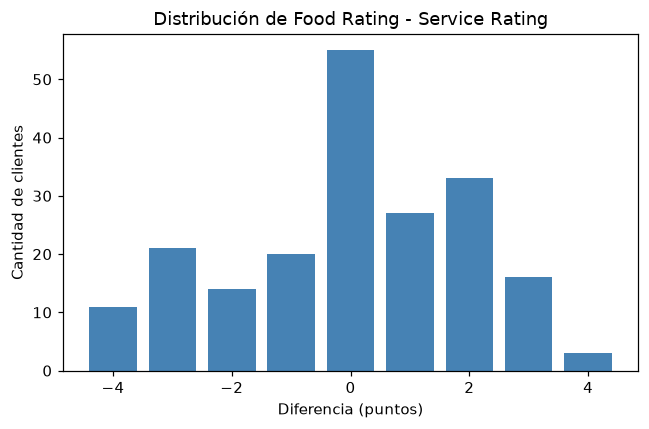

In [35]:
df_limpio['Edad'] = 2026 - df_limpio['YOB']
df_limpio['Grupo_Edad'] = pd.cut(df_limpio['Edad'], bins=[0, 24, 39, 54, 120], labels=['<25', '25-39', '40-54', '55+'])
df_limpio['Ciudad'] = df_limpio['Location'].str.split(', ').str[0]
df_limpio['Dif_Comida_Servicio'] = df_limpio['Food Rating'] - df_limpio['Service Rating']

print('Estados distintos en Location:', df_limpio['Location'].str.split(', ').str[1].unique().tolist())
display(df_limpio[['User ID', 'YOB', 'Edad', 'Grupo_Edad', 'Location', 'Ciudad',
                   'Food Rating', 'Service Rating', 'Dif_Comida_Servicio']].head(6))

conteo_edad = df_limpio['Grupo_Edad'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(conteo_edad.index.astype(str), conteo_edad.values, color='steelblue')
plt.title('Clientes por grupo de edad')
plt.xlabel('Grupo de edad')
plt.ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()

conteo_dif = df_limpio['Dif_Comida_Servicio'].value_counts().sort_index()
plt.figure(figsize=(6, 4))
plt.bar(conteo_dif.index, conteo_dif.values, color='steelblue')
plt.title('Distribución de Food Rating - Service Rating')
plt.xlabel('Diferencia (puntos)')
plt.ylabel('Cantidad de clientes')
plt.tight_layout()
plt.show()

El grupo de edad más grande es `25-39` (71 clientes) y el más chico `<25` (37). En `Dif_Comida_Servicio`, 55 clientes calificaron igual comida y servicio, 79 calificaron mejor la comida y 66 mejor el servicio, con diferencias de hasta 4 puntos. Es decir, para muchos clientes la comida y el servicio se evalúan de forma bastante independiente.

### 4.6 Codificación de variables categóricas, polinomiales y matriz de predictoras

- **Ordinales (`Alcohol`, `Smoker`):** tienen un orden natural de frecuencia (`Never` < `Socially` < `Often`), así que se codifican como `0`, `1` y `2`, asumiendo pasos iguales entre niveles.
- **Nominales (`Cuisines`, `Gender`, `Marital Status`, `Activity`, `Ciudad`):** no tienen orden, por lo que se usan variables dummy con `drop_first=True` para no inventar jerarquías.
- **Polinomiales:** no se generan. WOE/IV y LDA se usan para describir la separación entre clases y no se ajusta un modelo donde haga falta representar curvatura.

Con esto se arma la matriz de predictoras candidatas `X` (perfil y hábitos) y el objetivo `y = Calificacion_Alta`. Quedan fuera `User ID` (identificador), `Area code` (código nominal; la ubicación ya entra con `Ciudad`), `Overall Rating`, `Food Rating`, `Service Rating` y `Dif_Comida_Servicio` (fuga del objetivo). `YOB` se deja como candidata para que la regla de correlación de 5.2 decida entre ella y `Edad`.

In [36]:
mapa_frecuencia = {'Never': 0, 'Socially': 1, 'Often': 2}
df_limpio['Alcohol_ord'] = df_limpio['Alcohol'].map(mapa_frecuencia)
df_limpio['Smoker_ord'] = df_limpio['Smoker'].map(mapa_frecuencia)

cols_nominales = ['Cuisines', 'Gender', 'Marital Status', 'Activity', 'Ciudad']
df_codificado = pd.get_dummies(df_limpio, columns=cols_nominales, drop_first=True, dtype=int)

cols_pred_num = ['Edad', 'YOB', 'Budget', 'Alcohol_ord', 'Smoker_ord']
cols_dummies = [c for c in df_codificado.columns if c.startswith(tuple(f'{n}_' for n in cols_nominales))]
X = df_codificado[cols_pred_num + cols_dummies].astype('float64')
y = df_codificado['Calificacion_Alta']

cols_fuga = ['Overall Rating', 'Food Rating', 'Service Rating', 'Dif_Comida_Servicio', 'Calificacion_Alta']
print('Columnas de fuga dentro de X:', [c for c in cols_fuga if c in X.columns])

print(f'df_orig:       {df_orig.shape} | faltantes: {df_orig.isna().sum().sum()}')
print(f'df_limpio:     {df_limpio.shape} | faltantes: {df_limpio.isna().sum().sum()}')
print(f'df_codificado: {df_codificado.shape} (con dummies)')
print(f'X: {X.shape} | y: {y.shape}')
display(X.head(3))

Columnas de fuga dentro de X: []
df_orig:       (200, 15) | faltantes: 132
df_limpio:     (200, 21) | faltantes: 0
df_codificado: (200, 34) (con dummies)
X: (200, 23) | y: (200,)


,Edad,YOB,Budget,Alcohol_ord,Smoker_ord,Cuisines_Desconocido,Cuisines_Filipino,Cuisines_French,Cuisines_Indian,Cuisines_Italian,...,Marital Status_Married,Marital Status_Single,Activity_Student,Ciudad_Central Park,Ciudad_China Town,Ciudad_Market City,Ciudad_Riverdale,Ciudad_St. George,Ciudad_Upper East Side,Ciudad_Upper West Side
0,20.0,2006.0,3.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0
1,35.0,1991.0,3.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,...,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0
2,49.0,1977.0,5.0,2.0,2.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0


### 4.7 Comparación de escalas

`Edad` va de 17 a 71 años, `Budget` de 1 a 5 y los hábitos de 0 a 2, así que sus varianzas no son comparables. Se comparan `StandardScaler`, `MinMaxScaler` y `RobustScaler` sobre las predictoras numéricas de `X` antes de aplicar métodos sensibles a la escala (LDA y PCA). `Calificacion_Alta` no se escala porque es la etiqueta. Para esta comparación los escaladores se ajustan con los 200 registros; en LDA (5.4) el escalador se ajusta solo con el conjunto de entrenamiento.

,Orig_Media,Orig_Std,Std_Media,Std_Std,MinMax_Min,MinMax_Max,Robust_Mediana,Robust_IQR
Edad,41.20,16.27,-0.0,1.0,0.0,1.0,0.0,1.0
Budget,3.81,1.04,-0.0,1.0,0.0,1.0,0.0,1.0
Alcohol_ord,0.83,0.86,0.0,1.0,0.0,1.0,0.0,1.0
Smoker_ord,1.06,0.80,0.0,1.0,0.0,1.0,0.0,1.0


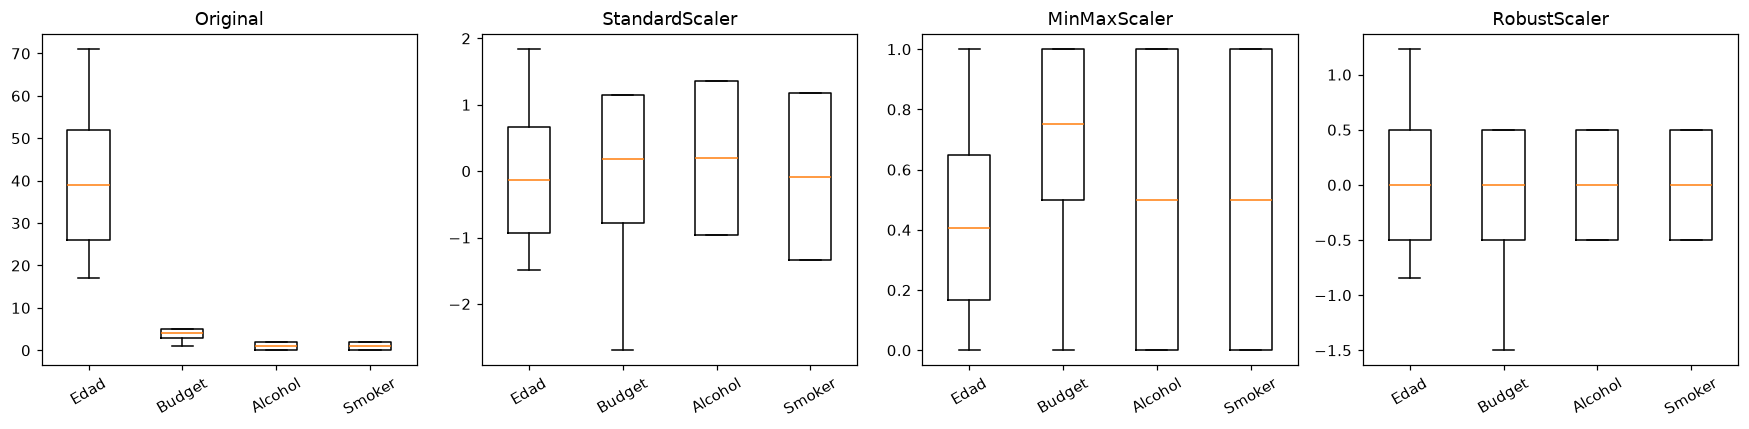

In [37]:
from sklearn.preprocessing import MinMaxScaler, RobustScaler

cols_escalar = ['Edad', 'Budget', 'Alcohol_ord', 'Smoker_ord']
X_num = X[cols_escalar]

escalados = {
    'StandardScaler': pd.DataFrame(StandardScaler().fit_transform(X_num), columns=cols_escalar),
    'MinMaxScaler': pd.DataFrame(MinMaxScaler().fit_transform(X_num), columns=cols_escalar),
    'RobustScaler': pd.DataFrame(RobustScaler().fit_transform(X_num), columns=cols_escalar),
}
X_std, X_mm, X_rob = escalados.values()

resumen_esc = pd.DataFrame({
    'Orig_Media': X_num.mean().round(2), 'Orig_Std': X_num.std().round(2),
    'Std_Media': X_std.mean().round(2), 'Std_Std': X_std.std().round(2),
    'MinMax_Min': X_mm.min().round(2), 'MinMax_Max': X_mm.max().round(2),
    'Robust_Mediana': X_rob.median().round(2), 'Robust_IQR': (X_rob.quantile(0.75) - X_rob.quantile(0.25)).round(2)
})
display(resumen_esc)

etiquetas = ['Edad', 'Budget', 'Alcohol', 'Smoker']
plt.figure(figsize=(16, 4))
for i, (nombre, datos) in enumerate([('Original', X_num)] + list(escalados.items())):
    plt.subplot(1, 4, i + 1)
    plt.boxplot(datos.values)
    plt.xticks(range(1, len(etiquetas) + 1), etiquetas, rotation=30)
    plt.title(nombre)
plt.tight_layout()
plt.show()

En la escala original, `Edad` (media 41.20, desv. est. 16.27) domina por completo frente a `Budget` (media 3.81, desv. est. 1.04) y los hábitos codificados de 0 a 2, lo cual sesgaría a los métodos sensibles a la escala como LDA y PCA. Los tres escaladores equilibran las variables: `StandardScaler` centra en media 0 y desv. est. 1, `MinMaxScaler` acota todo al rango `[0, 1]` y `RobustScaler` centra en mediana 0 con IQR igual a 1. Como en la Etapa 3 se comprobó que no existen valores atípicos extremos, se selecciona **`StandardScaler`** para LDA y PCA (ajustándolo únicamente con el conjunto de entrenamiento en LDA).

### Resumen de la Etapa 4

- Se partió de `df_orig` `(200, 15)` con 132 faltantes y todas las columnas en texto, y se obtuvo `df_limpio` `(200, 21)` con **0 faltantes** sin eliminar ningún registro.
- En el tratamiento de faltantes se recuperaron 25 calificaciones de forma exacta (`11` de `Food Rating` y `14` de `Service Rating`), se dedujeron `13` valores de hábitos a partir de `Often A S`, y los faltantes restantes se imputaron con mediana (`Area code`, `YOB`, `Budget`), moda respetando la regla lógica de hábitos, y `'Desconocido'` en `Cuisines` para no dar una ventaja artificial a `Japanese`.
- Se retiró `Often A S`, se creó la etiqueta `Calificacion_Alta`, se construyeron `Edad`, `Grupo_Edad`, `Ciudad` y `Dif_Comida_Servicio`, y se armó la matriz de predictoras `X` `(200, 23)` con codificación ordinal y variables dummy, verificando que ninguna columna de fuga esté dentro de `X`.

## Etapa 5. Selección y transformación de características: 

### 5.1 Selección por varianza

Calcular varianza en las variables numéricas pertinentes e identificar constantes o casi constantes. La varianza depende de las unidades: una columna en metros y la misma columna en milímetros tienen varianzas muy distintas. Un indicador poco frecuente puede ser predictivo aunque su varianza sea baja

Se calcula la varianza en escala original de las predictoras candidatas `X` (numéricas, ordinales y dummies) y se aplica `VarianceThreshold` con los umbrales vistos en el Módulo III (`0`, `0.01` y `0.10`). No entran el identificador, el objetivo ni las calificaciones que lo componen.

,Varianza
Edad,263.3500
YOB,263.3500
Budget,1.0839
Alcohol_ord,0.7411
Smoker_ord,0.6308
Marital Status_Single,0.2499
Marital Status_Married,0.2436
Gender_Male,0.2390
Activity_Student,0.2379
Ciudad_St. George,0.1900


Umbral 0: conserva 23; elimina []
Umbral 0.01: conserva 23; elimina []
Umbral 0.1: conserva 17; elimina ['Cuisines_Desconocido', 'Cuisines_Italian', 'Cuisines_Seafood', 'Ciudad_China Town', 'Ciudad_Market City', 'Ciudad_Upper West Side']


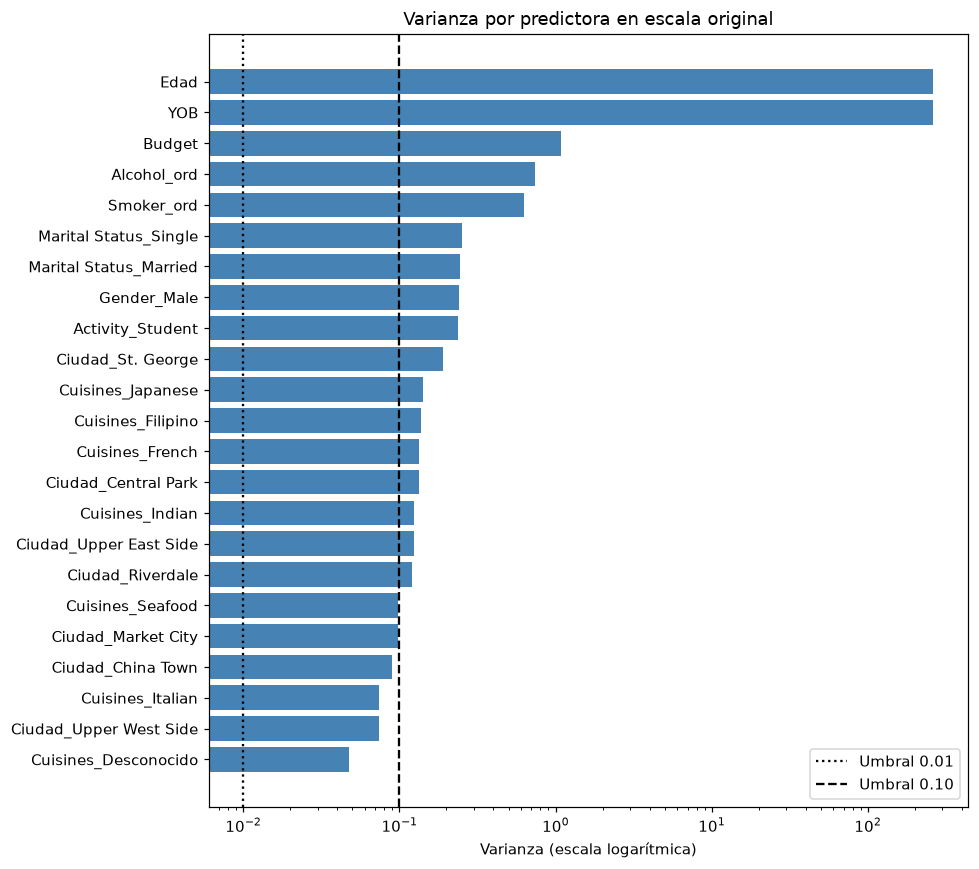

In [38]:
from sklearn.feature_selection import VarianceThreshold

varianzas = X.var(ddof=0).sort_values(ascending=False)
display(varianzas.round(4).rename('Varianza').to_frame())

for umbral_var in [0, 0.01, 0.10]:
    filtro = VarianceThreshold(threshold=umbral_var).fit(X)
    eliminadas = X.columns[~filtro.get_support()].tolist()
    print(f'Umbral {umbral_var}: conserva {filtro.get_support().sum()}; elimina {eliminadas}')

plt.figure(figsize=(9, 8))
plt.barh(varianzas.index[::-1], varianzas.values[::-1], color='steelblue')
plt.axvline(0.01, color='black', linestyle=':', label='Umbral 0.01')
plt.axvline(0.10, color='black', linestyle='--', label='Umbral 0.10')
plt.xscale('log')
plt.title('Varianza por predictora en escala original')
plt.xlabel('Varianza (escala logarítmica)')
plt.legend()
plt.tight_layout()
plt.show()

No hay variables constantes ni casi constantes: con umbrales `0` y `0.01` se conservan las **23 predictoras** (la varianza mínima es `Cuisines_Desconocido` con `0.0475`, que corresponde al 5% de clientes sin cocina registrada). Con umbral `0.10` se eliminarían 6 dummies de categorías poco frecuentes (`Cuisines_Desconocido`, `Cuisines_Italian`, `Cuisines_Seafood`, `Ciudad_China Town`, `Ciudad_Market City` y `Ciudad_Upper West Side`). Como la varianza de una variable binaria está acotada en $p(1-p) \le 0.25$ y una categoría minoritaria puede seguir siendo informativa (como se ve después con `Ciudad_Market City` en WOE y LDA), se descarta el corte rígido de `0.10` y pasan las 23 columnas al filtro por correlación.

### 5.2 Selección por correlación

Mostrar una matriz o mapa de calor para las características relevantes. Elegir Pearson para asociación lineal o Spearman para asociación monótona por rangos, y justificarlo. Si filtran pares altamente correlacionados, declarar un umbral (por ejemplo, 0.85) y una regla reproducible para decidir cuál conservar. Reportar las columnas retiradas y explicar el criterio.

La correlación mide asociación, no causalidad ni independencia. Correlación baja no descarta dependencia no lineal, un umbral por pares tampoco encuentra redundancia multivariable. 

Se usa la correlación de **Spearman** porque las predictoras numéricas son ordinales o discretas (`Budget` de 1 a 5, hábitos de 0 a 2) y Spearman mide asociaciones monótonas por rangos sin pedir normalidad ni linealidad. El mapa de calor muestra las predictoras numéricas y la regla de filtrado se aplica sobre todas las columnas de `X`, dummies incluidas. El umbral de redundancia es `|r| > 0.85`. La regla para decidir cuál conservar es la función `seleccionar_correlacion` del Módulo III: se recorren las columnas en orden y se conserva una columna solo si no supera el umbral con ninguna de las ya conservadas. Por eso las variables más interpretables (`Edad` antes que `YOB`) se colocan primero.

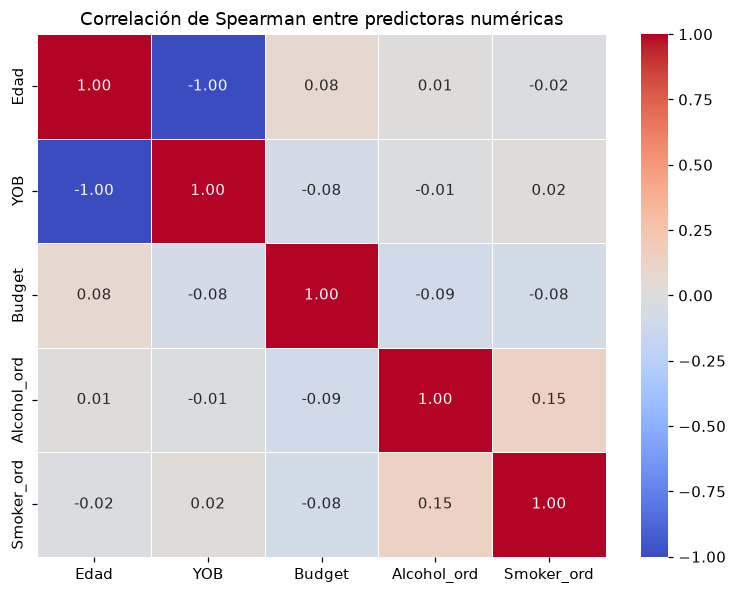

|Spearman|
variable_1             variable_2                        
Edad                   YOB                          1.000
Marital Status_Married Marital Status_Single        0.868
Edad                   Marital Status_Single        0.452
YOB                    Marital Status_Single        0.452
                       Marital Status_Married       0.397
Edad                   Marital Status_Married       0.397
                       Activity_Student             0.266
YOB                    Activity_Student             0.266

Columnas retiradas con |r| > 0.85: ['YOB', 'Marital Status_Single']
Predictoras finales: 21


In [39]:
def seleccionar_correlacion(datos, umbral=0.90, metodo='pearson'):
    matriz = datos.corr(method=metodo).abs()
    conservadas = []
    for columna in datos.columns:
        if not conservadas or not (matriz.loc[columna, conservadas] > umbral).any():
            conservadas.append(columna)
    return conservadas

corr_spearman = X[cols_pred_num].corr(method='spearman')

plt.figure(figsize=(7, 5.5))
sns.heatmap(corr_spearman, annot=True, fmt='.2f', cmap='coolwarm', vmin=-1, vmax=1, linewidths=0.5)
plt.title('Correlación de Spearman entre predictoras numéricas')
plt.tight_layout()
plt.show()

corr_x = X.corr(method='spearman')
mascara_superior = np.triu(np.ones(corr_x.shape, dtype=bool), k=1)
pares = corr_x.abs().where(mascara_superior).stack().sort_values(ascending=False)
pares.index.names = ['variable_1', 'variable_2']
display(pares.head(8).round(3).rename('|Spearman|').to_frame())

cols_sel = seleccionar_correlacion(X, umbral=0.85, metodo='spearman')
X_sel = X[cols_sel]
print('Columnas retiradas con |r| > 0.85:', [c for c in X.columns if c not in cols_sel])
print('Predictoras finales:', X_sel.shape[1])

Entre las predictoras numéricas independientes las correlaciones de Spearman son bajas, salvo la relación exacta entre `Edad` y `YOB` (`|r| = 1.000`). Al aplicar la regla `seleccionar_correlacion` con umbral `|r| > 0.85` sobre las 23 columnas de `X`, solo se retiran dos variables redundantes:
- **`YOB`**: se conserva `Edad` por ser más interpretable.
- **`Marital Status_Single`**: tiene `|r| = 0.868` con `Marital Status_Married` porque casados (84) y solteros (102) concentran el 93% de la muestra.

El siguiente par más correlacionado es `Edad` y `Marital Status_Single` (`0.452`), muy por debajo del umbral. Con esto la matriz depurada `X_sel` queda con **21 predictoras finales**.

### 5.3 WOE e Information Value

Usar WOE/IV solo si existe una variable objetivo **binaria** y la pregunta justifica una codificación supervisada. Definir explícitamente evento=1 y no evento=0. Para cada predictor mostrar la tabla de grupos, conteos por clase, distribuciones, WOE por grupo e IV total.

Para variables continuas, justificar bins y revisar tamaños, faltantes y conteos cero. Para variables categóricas, decidir qué categorías se agrupan y por qué. 


**Sí aplica.** El objetivo `Calificacion_Alta` es binario: evento = 1 (satisfacción alta, `Overall Rating >= 4`) y no evento = 0 (satisfacción baja o media). Se usa la función `calcular_woe_iv` del Módulo III, con `WOE = ln(d0 / d1)`, donde `d0` y `d1` son la proporción de no eventos y de eventos que cae en cada grupo, y suavizado `alpha = 0.5` para que un grupo sin eventos no dé un logaritmo infinito. Con esta convención, **WOE positivo significa que el grupo tiene más presencia relativa entre los clientes con satisfacción baja/media**, y WOE negativo, entre los de satisfacción alta.

Decisiones sobre los grupos:
- Se usan las variables originales de perfil y hábitos, no las dummies, para tener una tabla por variable: `Cuisines`, `Ciudad`, `Gender`, `Marital Status`, `Activity`, `Alcohol`, `Smoker`, `Budget` y `Edad`. No entran `Overall Rating`, `Food Rating`, `Service Rating` ni `Dif_Comida_Servicio`.
- `Edad` es continua y se agrupa en 5 cuantiles (unos 40 clientes por grupo). Con 200 registros, más bins dejarían grupos con muy pocos eventos.
- En `Budget` se juntan los niveles 1 y 2 (14 clientes) porque son adyacentes en la escala y por separado tienen muy pocos casos.
- `Cuisines = 'Desconocido'` se deja como su propio grupo (equivale a la categoría de faltantes) y `Cedar Hill` se deja sola en `Ciudad`; los grupos con menos de 5% de los registros se cuentan en la tabla.
- El IV se calcula sobre los 200 registros con fin descriptivo. Si el WOE se usara para codificar variables de un modelo, se tendría que aprender solo con entrenamiento.

In [40]:
def calcular_woe_iv(datos, objetivo, bins=10, alpha=0.5):
    respuesta = datos[objetivo]
    if respuesta.isna().any() or set(respuesta.unique()) != {0, 1}:
        raise ValueError('El objetivo debe contener ambas clases 0 y 1, sin faltantes.')
    tablas, resumen = [], []
    for variable in datos.columns.drop(objetivo):
        serie = datos[variable]
        if pd.api.types.is_numeric_dtype(serie) and serie.nunique() > bins:
            grupos = pd.qcut(serie, q=bins, duplicates='drop').astype('string')
        else:
            grupos = serie.astype('string')
        grupos = grupos.fillna('__FALTANTE__')
        conteos = pd.crosstab(grupos, respuesta).reindex(columns=[0, 1], fill_value=0)
        conteos.columns = ['no_eventos', 'eventos']
        numero_grupos = len(conteos)
        conteos['n'] = conteos['no_eventos'] + conteos['eventos']
        conteos['tasa_evento'] = conteos['eventos'] / conteos['n']
        conteos['dist_no_eventos'] = (conteos['no_eventos'] + alpha) / ((respuesta == 0).sum() + numero_grupos * alpha)
        conteos['dist_eventos'] = (conteos['eventos'] + alpha) / ((respuesta == 1).sum() + numero_grupos * alpha)
        conteos['WOE'] = np.log(conteos['dist_no_eventos'] / conteos['dist_eventos'])
        conteos['IV_grupo'] = (conteos['dist_no_eventos'] - conteos['dist_eventos']) * conteos['WOE']
        resumen.append({'variable': variable, 'IV': conteos['IV_grupo'].sum(), 'grupos': numero_grupos})
        conteos.index.name = 'grupo'
        conteos = conteos.reset_index()
        conteos.insert(0, 'variable', variable)
        tablas.append(conteos)
    return pd.DataFrame(resumen).sort_values('IV', ascending=False).reset_index(drop=True), pd.concat(tablas, ignore_index=True)

def interpretar_iv(valor):
    if valor < 0.02:
        return 'Insignificante'
    if valor < 0.10:
        return 'Débil'
    if valor < 0.30:
        return 'Moderada'
    if valor <= 0.50:
        return 'Fuerte'
    return 'Alta: revisar'

cols_woe = ['Cuisines', 'Ciudad', 'Gender', 'Marital Status', 'Activity', 'Alcohol', 'Smoker', 'Budget', 'Edad']
datos_woe = df_limpio[cols_woe + ['Calificacion_Alta']].copy()
datos_woe['Budget'] = datos_woe['Budget'].astype(str).replace({'1': '1-2', '2': '1-2'})

iv, woe = calcular_woe_iv(datos_woe, objetivo='Calificacion_Alta', bins=5, alpha=0.5)
iv['interpretacion'] = iv['IV'].map(interpretar_iv)
grupos_pequenos = woe.assign(pequeno=woe['n'] / len(datos_woe) < 0.05).groupby('variable')['pequeno'].sum()
iv['grupos_menores_5pct'] = iv['variable'].map(grupos_pequenos)
display(iv.round(4).style.hide(axis='index'))

variable,IV,grupos,interpretacion,grupos_menores_5pct
Marital Status,0.715100,3,Alta: revisar,0
Smoker,0.640500,3,Alta: revisar,0
Ciudad,0.226200,8,Moderada,1
Alcohol,0.206200,3,Moderada,0
Edad,0.171500,5,Moderada,0
Activity,0.152700,2,Moderada,0
Budget,0.119800,4,Moderada,0
Gender,0.107800,2,Moderada,0
Cuisines,0.084800,8,Débil,0


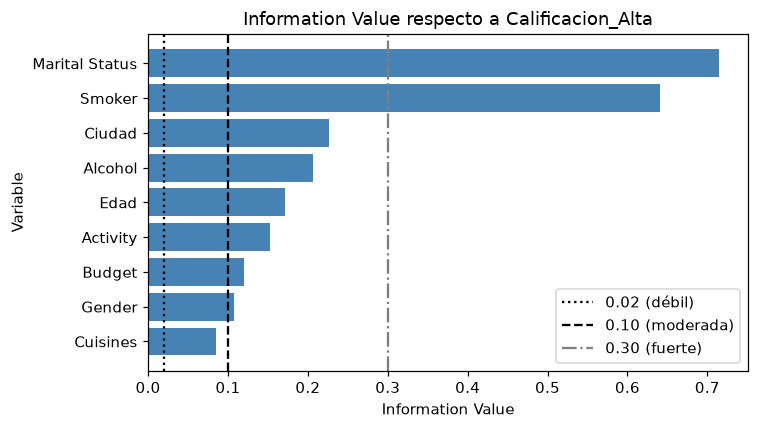

grupo,no_eventos,eventos,n,tasa_evento,dist_no_eventos,dist_eventos,WOE,IV_grupo
Divorced,2,12,14,0.857000,0.018000,0.200000,-2.419000,0.441000
Married,71,13,84,0.155000,0.509000,0.216000,0.857000,0.251000
Single,66,36,102,0.353000,0.473000,0.584000,-0.210000,0.023000


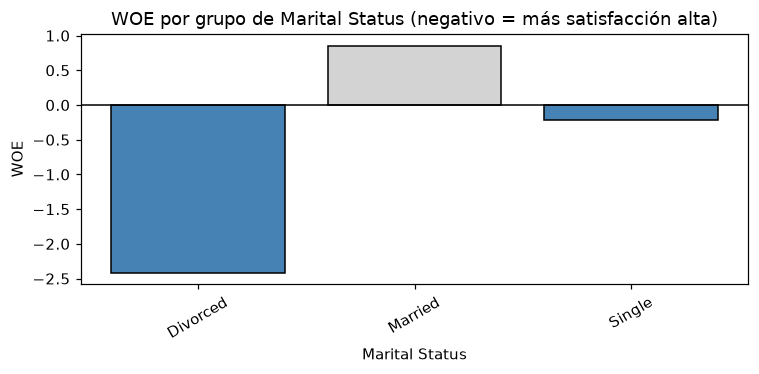

grupo,no_eventos,eventos,n,tasa_evento,dist_no_eventos,dist_eventos,WOE,IV_grupo
Never,51,6,57,0.105000,0.367000,0.104000,1.260000,0.331000
Often,34,36,70,0.514000,0.246000,0.584000,-0.866000,0.293000
Socially,54,19,73,0.260000,0.388000,0.312000,0.218000,0.017000


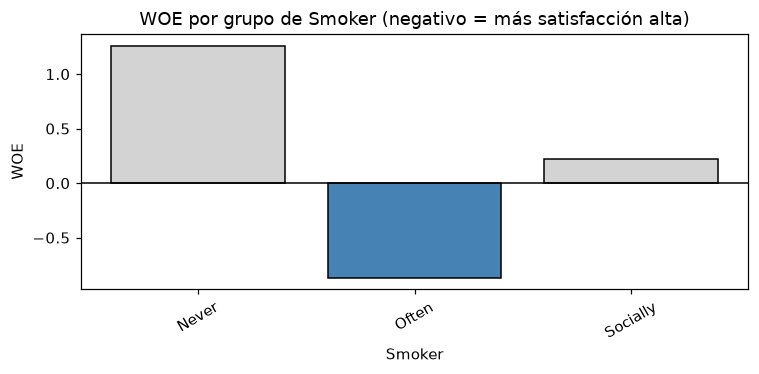

grupo,no_eventos,eventos,n,tasa_evento,dist_no_eventos,dist_eventos,WOE,IV_grupo
Cedar Hill,2,0,2,0.000000,0.017000,0.008000,0.821000,0.008000
Central Park,20,12,32,0.375000,0.143000,0.192000,-0.294000,0.014000
China Town,17,3,20,0.150000,0.122000,0.054000,0.821000,0.056000
Market City,10,12,22,0.545000,0.073000,0.192000,-0.963000,0.114000
Riverdale,22,6,28,0.214000,0.157000,0.100000,0.453000,0.026000
St. George,35,16,51,0.314000,0.248000,0.254000,-0.022000,0.000000
Upper East Side,21,8,29,0.276000,0.150000,0.131000,0.140000,0.003000
Upper West Side,12,4,16,0.250000,0.087000,0.069000,0.233000,0.004000


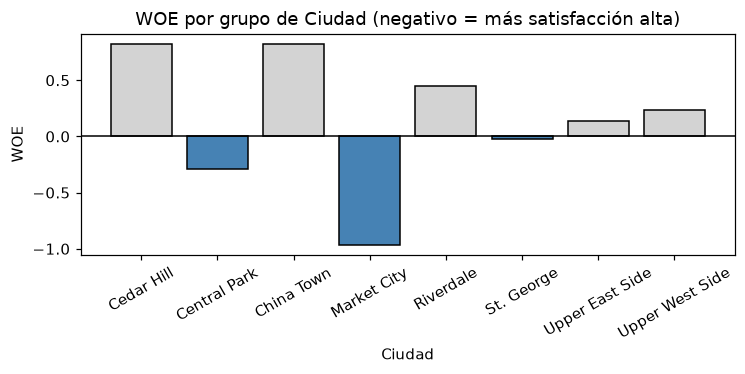

In [41]:
plt.figure(figsize=(7, 4))
iv_orden = iv.sort_values('IV')
plt.barh(iv_orden['variable'], iv_orden['IV'], color='steelblue')
plt.axvline(0.02, color='black', linestyle=':', label='0.02 (débil)')
plt.axvline(0.10, color='black', linestyle='--', label='0.10 (moderada)')
plt.axvline(0.30, color='gray', linestyle='-.', label='0.30 (fuerte)')
plt.title('Information Value respecto a Calificacion_Alta')
plt.xlabel('Information Value')
plt.ylabel('Variable')
plt.legend()
plt.tight_layout()
plt.show()

# WOE por grupo de las tres variables con mayor IV
for variable in iv['variable'].head(3):
    tabla = woe[woe['variable'] == variable]
    display(tabla.drop(columns='variable').round(3).style.hide(axis='index'))
    plt.figure(figsize=(7, 3.5))
    plt.bar(tabla['grupo'].astype(str), tabla['WOE'], color=np.where(tabla['WOE'] >= 0, 'lightgray', 'steelblue'), edgecolor='black')
    plt.axhline(0, color='black', linewidth=1)
    plt.title(f'WOE por grupo de {variable} (negativo = más satisfacción alta)')
    plt.xlabel(variable)
    plt.ylabel('WOE')
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

- **`Marital Status` (`IV = 0.7151`) y `Smoker` (`IV = 0.6405`)** superan el umbral de `0.50` (`Alta: revisar`). En una muestra de 200 registros esto debe interpretarse con cautela porque subgrupos pequeños con tasas muy marcadas inflan el IV: en `Marital Status`, `Divorced` tiene solo 14 clientes pero 85.7% de satisfacción alta (`WOE = -2.419`), frente a 35.3% en `Single` y 15.5% en `Married` (`WOE = +0.857`).
- En **`Smoker`** se observa una tendencia monótona clara: quienes fuman con frecuencia (`Often`) alcanzan 51.4% de satisfacción alta (`WOE = -0.866`), `Socially` 26.0% y `Never` solo 10.5% (`WOE = +1.260`).
- Seis variables tienen poder **moderado**: `Ciudad` (`0.2262`), `Alcohol` (`0.2062`), `Edad` (`0.1715`), `Activity` (`0.1527`), `Budget` (`0.1198`) y `Gender` (`0.1078`). En `Ciudad` sobresalen `Market City` (54.5% de satisfacción alta, `WOE = -0.963`) y `Central Park` (37.5%), mientras que `China Town` (15.0%) y `Riverdale` (21.4%) presentan las tasas más bajas (`Cedar Hill` solo tiene 2 clientes, así que su 0% no es estable).
- **`Cuisines`** muestra poder **débil** (`IV = 0.0848`): por sí sola, la cocina preferida diferencia poco a los clientes con satisfacción alta.

### 5.4 Análisis discriminante lineal (LDA)

LDA es supervisado: usa las etiquetas para buscar combinaciones que separen clases. Si es pertinente, documentar escalado, variables de entrada, priors y número de componentes. El máximo de ejes discriminantes es $\min(p, C-1)$, donde $p$ es el número de características y $C$ el número de clases. Con dos clases solo hay un eje discriminante.

Distinguir LDA como transformador para visualizar/reducir dimensiones de LDA como clasificador. Mostrar una proyección 1D o 2D cuando sea posible y explicar qué clases se separan. 

**Sí aplica.** Hay una etiqueta binaria (`Calificacion_Alta`), así que LDA puede buscar la combinación de predictoras que mejor separa a los clientes con satisfacción alta de los demás. Se usa principalmente como **transformador** para visualizar esa separación en un eje; su exactitud como clasificador solo se reporta como referencia.

- **Entradas:** las predictoras finales `X_sel` de 5.2 (`Edad`, `Budget`, `Alcohol_ord`, `Smoker_ord` y las dummies de cocina, género, estado civil, actividad y ciudad). No entran `Overall Rating`, `Food Rating`, `Service Rating` ni `Dif_Comida_Servicio`.
- **Partición:** 75% entrenamiento y 25% prueba, estratificada por la clase y con `random_state=42`, como en el Módulo III.
- **Escalado:** `StandardScaler` ajustado solo en entrenamiento y aplicado sin recalcular a prueba.
- **Priors:** las proporciones de clase en entrenamiento (cerca de 70% / 30%).
- **Componentes:** con dos clases el máximo es `min(p, C - 1) = 1`, así que solo hay un eje (`LD1`).

In [42]:
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X_sel, y, test_size=0.25, stratify=y, random_state=42)

escalador_lda = StandardScaler().fit(X_train)
X_train_std = escalador_lda.transform(X_train)
X_test_std = escalador_lda.transform(X_test)

lda = LinearDiscriminantAnalysis(n_components=1, solver='svd')
lda.fit(X_train_std, y_train)
Z_train = lda.transform(X_train_std)[:, 0]
Z_test = lda.transform(X_test_std)[:, 0]

print('Entrenamiento:', X_train_std.shape, '| Prueba:', X_test_std.shape)
print('Priors (clase 0, clase 1):', lda.priors_.round(3))
print(f'Exactitud en entrenamiento: {lda.score(X_train_std, y_train):.3f}')
print(f'Exactitud en prueba:        {lda.score(X_test_std, y_test):.3f}')
print(f'Referencia (siempre predecir clase 0) en prueba: {(y_test == 0).mean():.3f}')

medias_ld1 = pd.DataFrame({'Entrenamiento': pd.Series(Z_train).groupby(y_train.values).mean(),
                           'Prueba': pd.Series(Z_test).groupby(y_test.values).mean()}).round(3)
medias_ld1.index.name = 'Calificacion_Alta'
print('Media de LD1 por clase:')
display(medias_ld1)

pesos_ld1 = pd.Series(lda.scalings_[:, 0], index=X_sel.columns)
print('Pesos de LD1 con mayor magnitud (predictoras estandarizadas):')
display(pesos_ld1.reindex(pesos_ld1.abs().sort_values(ascending=False).index).head(8).round(3).rename('Peso LD1').to_frame())

Entrenamiento: (150, 21) | Prueba: (50, 21)
Priors (clase 0, clase 1): [0.693 0.307]
Exactitud en entrenamiento: 0.807
Exactitud en prueba:        0.820
Referencia (siempre predecir clase 0) en prueba: 0.700
Media de LD1 por clase:


,Entrenamiento,Prueba
Calificacion_Alta,,
0,-0.438,-0.529
1,0.990,0.760


Pesos de LD1 con mayor magnitud (predictoras estandarizadas):


,Peso LD1
Ciudad_Market City,0.757
Ciudad_Central Park,0.677
Smoker_ord,0.573
Marital Status_Married,-0.504
Ciudad_St. George,0.477
Ciudad_Upper East Side,0.319
Activity_Student,-0.310
Ciudad_China Town,0.285


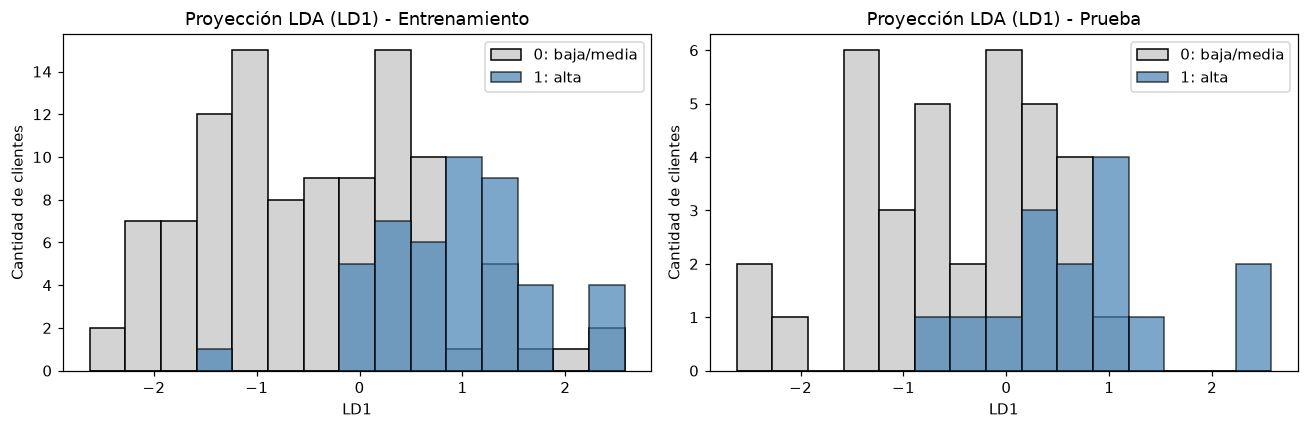

In [43]:
bordes = np.linspace(min(Z_train.min(), Z_test.min()), max(Z_train.max(), Z_test.max()), 16)
plt.figure(figsize=(12, 4))
for i, (nombre, z, etiqueta) in enumerate([('Entrenamiento', Z_train, y_train), ('Prueba', Z_test, y_test)]):
    plt.subplot(1, 2, i + 1)
    plt.hist(z[etiqueta.values == 0], bins=bordes, color='lightgray', edgecolor='black', label='0: baja/media')
    plt.hist(z[etiqueta.values == 1], bins=bordes, color='steelblue', edgecolor='black', alpha=0.7, label='1: alta')
    plt.title(f'Proyección LDA (LD1) - {nombre}')
    plt.xlabel('LD1')
    plt.ylabel('Cantidad de clientes')
    plt.legend()
plt.tight_layout()
plt.show()

En el único eje discriminante `LD1`, las medias de ambas clases quedan separadas tanto en entrenamiento (`-0.438` para clase 0 contra `+0.990` para clase 1) como en prueba (`-0.529` contra `+0.760`), aunque en los histogramas se observa un traslape moderado alrededor de `0`. Como clasificador de referencia, LDA alcanza **0.807** de exactitud en entrenamiento y **0.820** en prueba, superando en 12 puntos porcentuales la línea base de predecir siempre la clase mayoritaria (`0.700`).

Los pesos de mayor magnitud en `LD1` coinciden con WOE/IV: `Ciudad_Market City` (`+0.757`), `Ciudad_Central Park` (`+0.677`), `Smoker_ord` (`+0.573`) y `Ciudad_St. George` (`+0.477`) empujan hacia la clase de satisfacción alta, mientras que `Marital Status_Married` (`-0.504`) y `Activity_Student` (`-0.310`) se asocian con valores negativos en el eje discriminante.

### 5.5 Análisis de componentes principales (PCA)

PCA es no supervisado: encuentra combinaciones que conservan varianza, sin consultar la etiqueta. Estandarizar las variables cuando sus escalas/unidades sean distintas y justificar el escalado cuando deban conservarse magnitudes originales. El ajuste y el escalador se aprenden solo en entrenamiento.

Mostrar varianza explicada individual y acumulada, justificar cuántos componentes se conservan. Interpretar los pesos principales y, si ayuda, graficar las primeras componentes. 

PCA es no supervisado, así que no consulta `Calificacion_Alta`. Se aplica sobre las mismas predictoras finales `X_sel` que LDA (perfil y hábitos), estandarizadas con `StandardScaler` como se decidió en 4.7; no entran el objetivo ni las calificaciones de comida y servicio. Como no se usa la etiqueta, el escalador y el PCA se ajustan con los 200 registros. Se conservan los componentes necesarios para explicar al menos 70% de la varianza.

Componente,Varianza explicada (%),Varianza acumulada (%)
PC1,9.010000,9.010000
PC2,8.400000,17.420000
PC3,7.600000,25.020000
PC4,7.160000,32.180000
PC5,7.000000,39.180000
PC6,6.550000,45.730000
PC7,6.150000,51.880000
PC8,5.650000,57.530000
PC9,5.440000,62.970000
PC10,5.140000,68.110000


Componentes para explicar al menos 70%: 11 de 21
Pesos con mayor magnitud en PC1 y PC2:


,PC1
Marital Status_Married,0.444
Ciudad_Central Park,-0.424
Edad,0.414
Budget,0.259
Activity_Student,-0.245


,PC2
Ciudad_Riverdale,0.372
Cuisines_Indian,-0.348
Cuisines_Italian,0.317
Ciudad_China Town,-0.315
Ciudad_Market City,-0.286


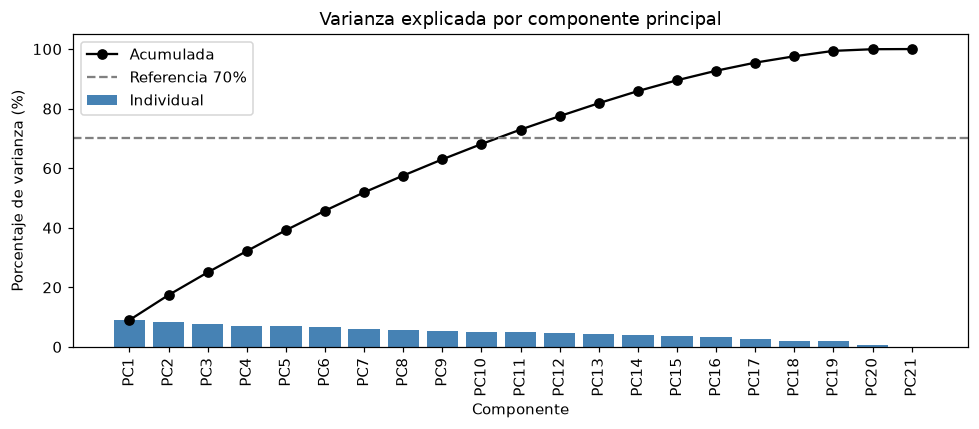

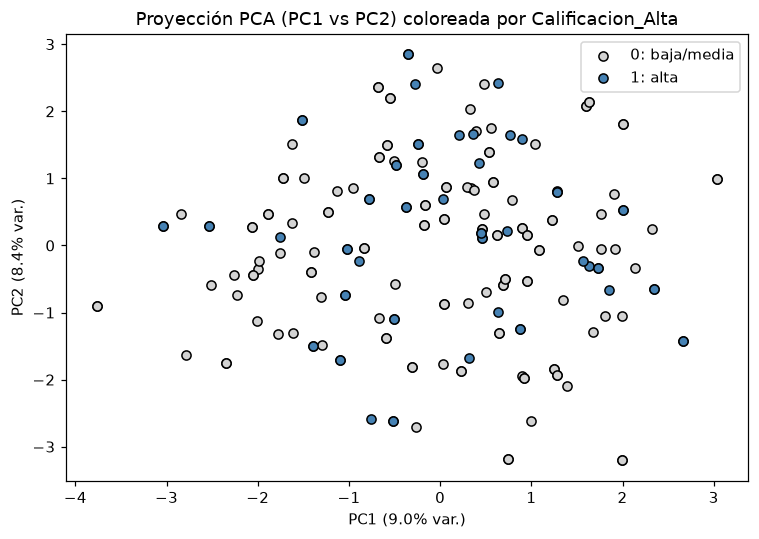

In [44]:
from sklearn.decomposition import PCA

X_pca_std = StandardScaler().fit_transform(X_sel)

pca = PCA()
componentes = pca.fit_transform(X_pca_std)
var_ind = pca.explained_variance_ratio_
var_acum = np.cumsum(var_ind)
n_comp = int(np.argmax(var_acum >= 0.70) + 1)
pcs = [f'PC{i+1}' for i in range(len(var_ind))]

display(pd.DataFrame({
    'Componente': pcs,
    'Varianza explicada (%)': (var_ind * 100).round(2),
    'Varianza acumulada (%)': (var_acum * 100).round(2)
}).head(n_comp + 2).style.hide(axis='index'))
print(f'Componentes para explicar al menos 70%: {n_comp} de {len(pcs)}')

loadings = pd.DataFrame(pca.components_[:2].T, index=X_sel.columns, columns=['PC1', 'PC2']).round(3)
print('Pesos con mayor magnitud en PC1 y PC2:')
for pc in ['PC1', 'PC2']:
    display(loadings[pc].reindex(loadings[pc].abs().sort_values(ascending=False).index).head(5).to_frame())

plt.figure(figsize=(9, 4))
plt.bar(pcs, var_ind * 100, color='steelblue', label='Individual')
plt.plot(pcs, var_acum * 100, color='black', marker='o', label='Acumulada')
plt.axhline(70, color='gray', linestyle='--', label='Referencia 70%')
plt.title('Varianza explicada por componente principal')
plt.xlabel('Componente')
plt.ylabel('Porcentaje de varianza (%)')
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.show()

# La etiqueta solo se usa para colorear, después de ajustar el PCA
plt.figure(figsize=(7, 5))
for clase, color, nombre in [(0, 'lightgray', '0: baja/media'), (1, 'steelblue', '1: alta')]:
    m = (y == clase).values
    plt.scatter(componentes[m, 0], componentes[m, 1], color=color, edgecolor='black', label=nombre)
plt.title('Proyección PCA (PC1 vs PC2) coloreada por Calificacion_Alta')
plt.xlabel(f'PC1 ({var_ind[0]*100:.1f}% var.)')
plt.ylabel(f'PC2 ({var_ind[1]*100:.1f}% var.)')
plt.legend()
plt.tight_layout()
plt.show()

La varianza queda muy repartida entre las 21 predictoras debido a la presencia de múltiples variables dummy poco correlacionadas entre sí: `PC1` explica `9.01%`, `PC2` `8.40%` (`17.42%` acumuladas) y se necesitan **11 de 21 componentes** para superar el umbral de 70% (`72.96%`).

- **`PC1`** refleja un eje de perfil socio-demográfico que contrapone clientes casados (`+0.444`), de mayor edad (`+0.414`) y mayor presupuesto (`+0.259`) frente a residentes de `Central Park` (`-0.424`) y estudiantes (`-0.245`).
- **`PC2`** captura principalmente diferencias de zona y cocina (`Ciudad_Riverdale` `+0.372` y `Cuisines_Italian` `+0.317` frente a `Cuisines_Indian` `-0.348`, `Ciudad_China Town` `-0.315` y `Ciudad_Market City` `-0.286`).

Al proyectar `PC1` vs `PC2` y colorear después con `Calificacion_Alta`, ambas clases aparecen mezcladas. Esto confirma la diferencia entre ambos métodos: PCA conserva la varianza global sin ver la etiqueta, mientras que LDA busca la dirección que separa las clases.

## Etapa 6. Respuesta a las preguntas del proyecto

Se responden las preguntas de la Etapa 1 con `df_limpio`. En los análisis por tipo de cocina se excluyen los 10 registros con `Cuisines = 'Desconocido'`.

### 6.1 ¿Qué cocinas prefieren más los clientes y cómo se califican?

,Clientes,Comida_Prom,Servicio_Prom,General_Prom,Presupuesto_Prom,Porcentaje (%)
Cuisines,,,,,,
Japanese,34,3.94,3.35,3.65,4.06,17.9
Filipino,33,2.73,3.36,3.05,3.73,17.4
French,32,3.28,2.91,3.09,3.94,16.8
Indian,29,2.66,3.55,3.10,3.38,15.3
Chinese,24,3.46,3.08,3.27,4.04,12.6
Seafood,22,3.23,3.05,3.14,3.55,11.6
Italian,16,3.25,3.38,3.31,3.81,8.4


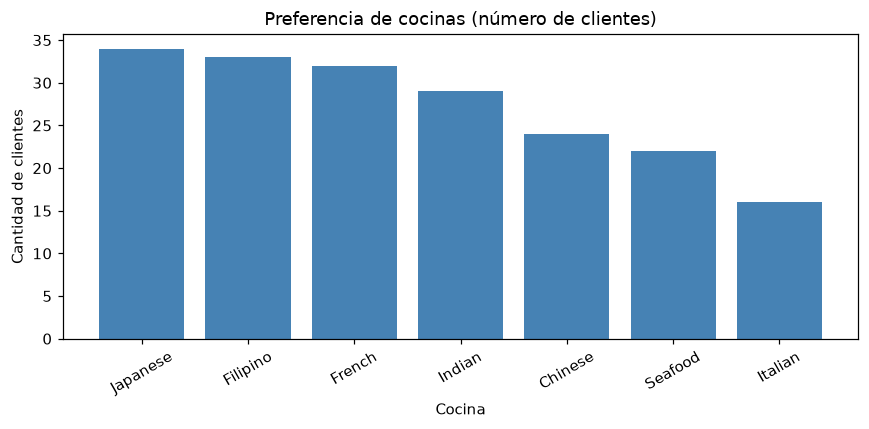

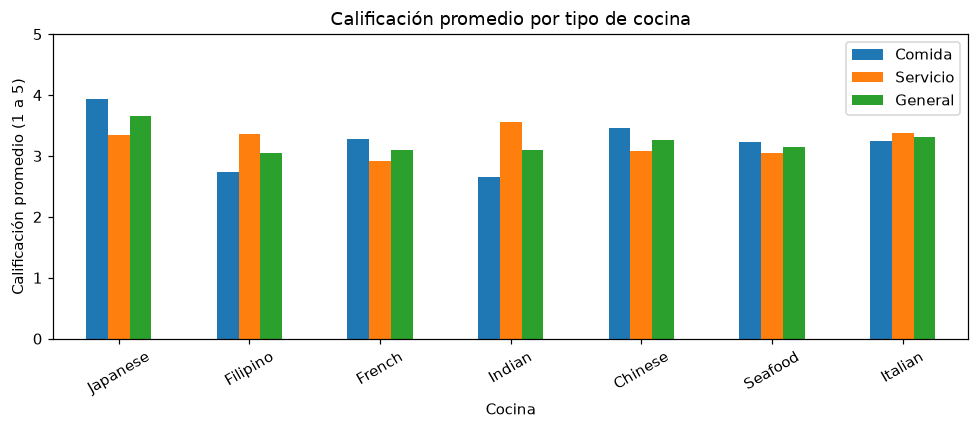

In [45]:
df_cocina = df_limpio[df_limpio['Cuisines'] != 'Desconocido']

resumen_cocina = df_cocina.groupby('Cuisines').agg(
    Clientes=('User ID', 'count'),
    Comida_Prom=('Food Rating', 'mean'),
    Servicio_Prom=('Service Rating', 'mean'),
    General_Prom=('Overall Rating', 'mean'),
    Presupuesto_Prom=('Budget', 'mean')
).round(2).sort_values('Clientes', ascending=False)
resumen_cocina['Porcentaje (%)'] = (resumen_cocina['Clientes'] / len(df_cocina) * 100).round(1)
display(resumen_cocina)

plt.figure(figsize=(8, 4))
plt.bar(resumen_cocina.index, resumen_cocina['Clientes'], color='steelblue')
plt.title('Preferencia de cocinas (número de clientes)')
plt.xlabel('Cocina')
plt.ylabel('Cantidad de clientes')
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

resumen_cocina[['Comida_Prom', 'Servicio_Prom', 'General_Prom']].plot(kind='bar', figsize=(9, 4))
plt.title('Calificación promedio por tipo de cocina')
plt.xlabel('Cocina')
plt.ylabel('Calificación promedio (1 a 5)')
plt.ylim(0, 5)
plt.xticks(rotation=30)
plt.legend(['Comida', 'Servicio', 'General'])
plt.tight_layout()
plt.show()

- **Preferencia:** `Japanese` es la cocina con más clientes (34, 17.9%), pero casi empata con `Filipino` (33) y `French` (32); con 190 registros, una diferencia de uno o dos clientes no es concluyente. `Italian` es la menos elegida (16, 8.4%).
- **Calificaciones:** `Japanese` tiene la mejor calificación general (3.65) y la mejor en comida (3.94). Le siguen `Italian` (3.31) y `Chinese` (3.27). `Filipino` tiene la general más baja (3.05).
- `Indian` es el caso más contrastante: la mejor en servicio (3.55) pero la peor en comida (2.66). `French` tiene el servicio más bajo (2.91).

### 6.2 ¿Cambia la preferencia según el presupuesto o la ubicación?

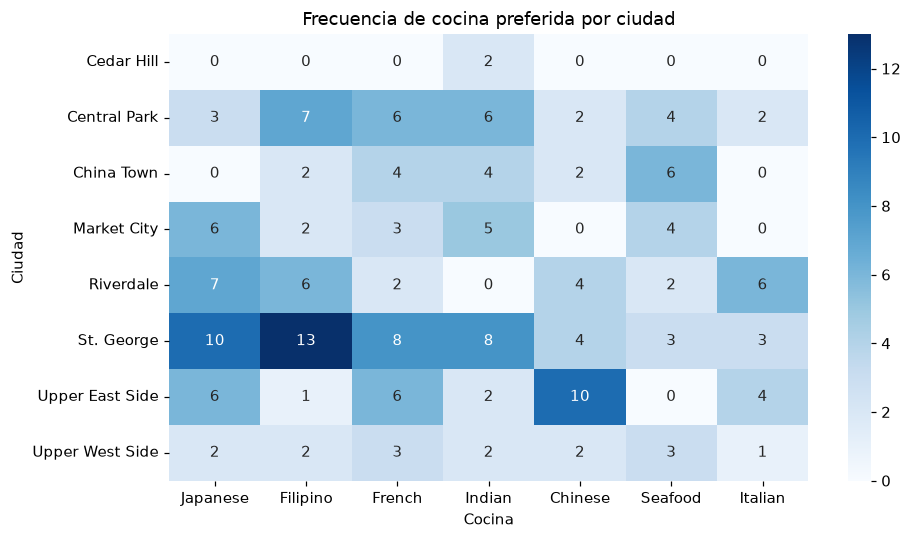

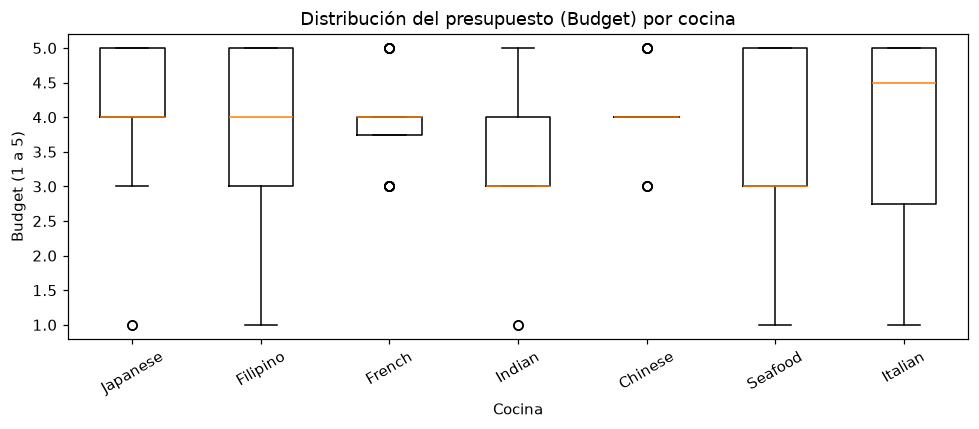

,Clientes,Cocina más frecuente
Ciudad,,
St. George,49,Filipino
Central Park,30,Filipino
Upper East Side,29,Chinese
Riverdale,27,Japanese
Market City,20,Japanese
China Town,18,Seafood
Upper West Side,15,French
Cedar Hill,2,Indian


Cuisines,Japanese,Filipino,French,Indian,Chinese,Seafood,Italian
Budget,,,,,,,
1,20.0,20.0,0.0,20.0,0.0,20.0,20.0
2,0.0,0.0,0.0,0.0,0.0,50.0,50.0
3,10.5,22.8,14.0,29.8,7.0,14.0,1.8
4,19.0,12.7,28.6,7.9,23.8,3.2,4.8
5,25.0,17.9,10.7,8.9,8.9,14.3,14.3


In [46]:
tabla_ciudad = pd.crosstab(df_cocina['Ciudad'], df_cocina['Cuisines'])
orden_cocinas = resumen_cocina.index.tolist()

plt.figure(figsize=(9, 5))
sns.heatmap(tabla_ciudad[orden_cocinas], annot=True, fmt='d', cmap='Blues')
plt.title('Frecuencia de cocina preferida por ciudad')
plt.xlabel('Cocina')
plt.ylabel('Ciudad')
plt.tight_layout()
plt.show()

datos_budget = [df_cocina.loc[df_cocina['Cuisines'] == c, 'Budget'] for c in orden_cocinas]
plt.figure(figsize=(9, 4))
plt.boxplot(datos_budget)
plt.xticks(range(1, len(orden_cocinas) + 1), orden_cocinas, rotation=30)
plt.title('Distribución del presupuesto (Budget) por cocina')
plt.xlabel('Cocina')
plt.ylabel('Budget (1 a 5)')
plt.tight_layout()
plt.show()

# Cocina más frecuente por ciudad y porcentaje de clientes por nivel de presupuesto
display(pd.DataFrame({'Clientes': tabla_ciudad.sum(axis=1), 'Cocina más frecuente': tabla_ciudad.idxmax(axis=1)})
        .sort_values('Clientes', ascending=False))
display((pd.crosstab(df_cocina['Budget'], df_cocina['Cuisines'], normalize='index') * 100).round(1)[orden_cocinas])

- **Ubicación:** la cocina más frecuente cambia por zona. `Filipino` domina en St. George (13 de 49) y Central Park (7 de 30); `Chinese` se concentra en Upper East Side (10 de sus 24 clientes viven ahí); `Japanese` lidera en Riverdale y Market City, y `Seafood` en China Town. Cedar Hill solo tiene 2 registros y Upper West Side tiene empates, así que en esas zonas no se puede hablar de una preferencia.
- **Presupuesto:** `Japanese` (4.06) y `Chinese` (4.04) tienen el presupuesto promedio más alto, e `Indian` (3.38) y `Seafood` (3.55) el más bajo, con mediana de 3. Entre los clientes con presupuesto 3 la cocina más elegida es `Indian` (29.8%), con presupuesto 4 es `French` (28.6%) y con presupuesto 5 es `Japanese` (25.0%). Los niveles 1 y 2 tienen solo 10 y 4 clientes, por lo que sus porcentajes no son confiables.

### 6.3 ¿Qué influye más en la calificación general, la comida o el servicio?

Correlación de Spearman con Overall Rating:
Food Rating       0.693
Service Rating    0.764
Overall Rating    1.000
Name: Overall Rating, dtype: float64

Promedio y desviación estándar:


,Food Rating,Service Rating,Overall Rating
mean,3.22,3.23,3.22
std,1.41,1.53,1.08


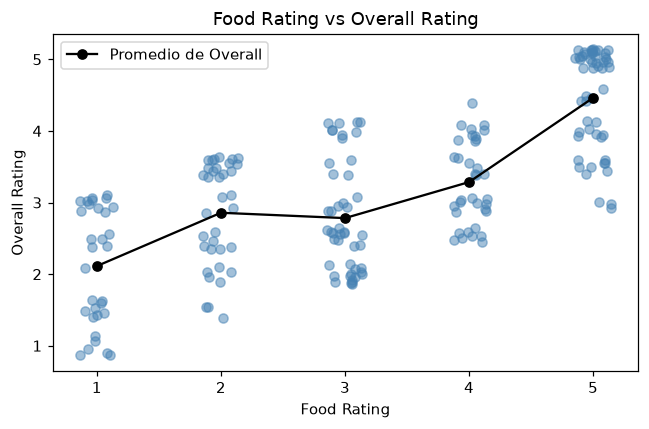

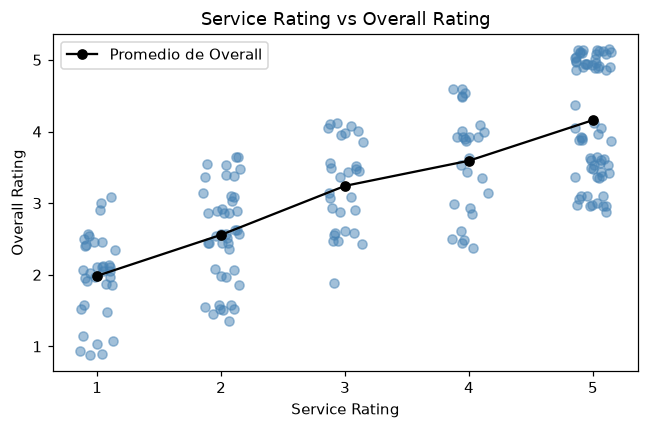

In [47]:
print('Correlación de Spearman con Overall Rating:')
print(df_limpio[['Food Rating', 'Service Rating', 'Overall Rating']].corr(method='spearman')['Overall Rating'].round(3))
print('\nPromedio y desviación estándar:')
display(df_limpio[['Food Rating', 'Service Rating', 'Overall Rating']].agg(['mean', 'std']).round(2))

# Se suma un pequeño ruido a los puntos para que no se encimen
rng = np.random.default_rng(42)
for col in ['Food Rating', 'Service Rating']:
    medias = df_limpio.groupby(col)['Overall Rating'].mean()
    plt.figure(figsize=(6, 4))
    plt.scatter(df_limpio[col] + rng.uniform(-0.15, 0.15, len(df_limpio)),
                df_limpio['Overall Rating'] + rng.uniform(-0.15, 0.15, len(df_limpio)),
                color='steelblue', alpha=0.5)
    plt.plot(medias.index, medias.values, color='black', marker='o', label='Promedio de Overall')
    plt.title(f'{col} vs Overall Rating')
    plt.xlabel(col)
    plt.ylabel('Overall Rating')
    plt.legend()
    plt.tight_layout()
    plt.show()

- `Overall Rating` es, por construcción, el promedio exacto de `Food Rating` y `Service Rating`, así que ambas pesan 50% en la fórmula.
- Aun así, `Service Rating` tiene mayor correlación con `Overall Rating` (0.764 contra 0.693) porque tiene más dispersión (desv. est. 1.53 contra 1.41) y las dos calificaciones casi no se relacionan entre sí. En la práctica, las diferencias en la calificación general entre clientes se explican un poco más por el servicio que por la comida.
- En promedio, comida (3.22) y servicio (3.23) se califican igual.

### Conclusiones y limitaciones

1. **Cocinas preferidas:** `Japanese`, `Filipino` y `French` concentran poco más de la mitad de los clientes con cocina registrada y están prácticamente empatadas; `Italian` es la menos elegida. Si se hubieran imputado los 10 faltantes de `Cuisines` con la moda, `Japanese` habría aparecido con 44 clientes y una ventaja que los datos no respaldan.
2. **Calificaciones por cocina:** `Japanese` es la mejor evaluada en comida y en general. `Indian` muestra que una cocina puede tener buen servicio y mala comida al mismo tiempo, lo que sugiere revisar ambos aspectos por separado.
3. **Presupuesto y ubicación:** la preferencia cambia más por zona que por presupuesto. Hay concentraciones claras (`Chinese` en Upper East Side, `Filipino` en St. George), mientras que por presupuesto solo se ve que `Japanese` y `Chinese` atraen a clientes de presupuesto más alto e `Indian` a los de presupuesto medio.
4. **Comida vs. servicio:** ambas pesan igual en la fórmula de `Overall Rating`, pero el servicio explica un poco más de la variación entre clientes por tener calificaciones más polarizadas.
5. **Perfil asociado a satisfacción alta (WOE/IV, LDA y PCA):** el tipo de cocina por sí solo tiene poder débil (`IV = 0.0848`); las diferencias más fuertes aparecen en `Marital Status` (`IV = 0.7151`, mayor satisfacción en `Divorced` y `Single` que en `Married`), `Smoker` (`IV = 0.6405`, mayor en `Often` que en `Never`) y `Ciudad` (`IV = 0.2262`, destacando `Market City` y `Central Park`). Al combinar las variables de perfil en LDA sin fuga de información se logra 82.0% de exactitud en prueba frente a 70.0% de referencia, mientras que PCA necesita 11 de 21 componentes para retener 72.96% de varianza y no separa las clases en sus primeros dos ejes.
6. **Limitaciones:** la muestra es pequeña (200 clientes), no hay fechas ni montos reales de compra, varias zonas y niveles de presupuesto tienen muy pocos registros, y todos los resultados son descriptivos: muestran asociaciones en esta muestra, no causas.

# Entregables obligatorios

Cada equipo entregará estos tres productos:

### 1. Presentación con diapositivas

**(15 min de presentación y 5 min de preguntas):** Debe comunicar el problema, los datos asignados, el método de procesamiento, los hallazgos más importantes, las limitaciones y las conclusiones. Incluyan figuras legibles, títulos y una explicación breve de qué evidencia aporta cada una. Todas las personas del equipo deben poder explicar el trabajo y responder preguntas.

### 2. Reporte digital del trabajo realizado

El **reporte** se entregará como documento digital elaborado en computadora; **no se aceptan fotografías de hojas o cuadernos**. Como mínimo, debe incluir:

- Nombre y apellidos de todas las personas integrantes.
- Descripción del problema, pregunta, objetivo y solución propuesta.
- Fuente, liga del dataset, descripción de datos y diccionario de variables.
- **Proceso realizado (Etapa 1-5)**: extracción, limpieza, decisiones de transformación y métodos utilizados.
- Resultados con figuras/tablas y su interpretación.
- **Un capítulo que describa la solución que se propuso para el problema.**
- **El código generado por el equipo para realizar el proyecto.** Puede organizarse en bloques legibles en el reporte y complementarse con el notebook entregado por separado, debe quedar claro qué código produjo los resultados.
- **Una sección de conclusiones.**
- Limitaciones, referencias y explicación de las decisiones relevantes.

**Impresión:** no es necesario imprimir a color. Diseñen las figuras para que se distingan en escala de grises, usen tipos de línea, marcadores, etiquetas o patrones además del color.

**Estructura sugerida del reporte:** 
- portada e integrantes
- resumen
- contexto de los datos y fuente
- Metodología/proceso
- Capítulo de solución propuesta (Etapas 1- 5)
- Resultados y figuras
- Limitaciones
- Conclusiones, referencias
- Apéndice de código si se requiere.

### 3. Código en Jupyter notebook

El notebook debe documentar el proceso completo: código, análisis, comentarios, tablas y gráficas. Debe ejecutarse en orden y ser comprensible para alguien que no participó en su elaboración.

- Incluir nombres completos, equipo, pregunta y liga asignada.
- Mantener comentarios y texto Markdown que expliquen qué se hace y por qué.
- No omitir celdas necesarias ni depender de variables creadas manualmente en otra sesión.
- Usar rutas relativas, indicar formato y fuentes de datos y no incluir credenciales privadas.
- Mostrar las figuras y salidas que se discuten en el reporte.
- Registrar decisiones, parámetros y semilla aleatoria cuando aplique.
- Ejecutar desde un kernel limpio antes de entregar y revisar que no haya errores.
- Mantener la versión original de los datos; no guardar archivos derivados sobre el original sin indicarlo.